# Acoustic Source Localization with Unknown Attenuation — Grey Wolf Optimizer

**Swarm Intelligence mini-project · optimizer: GWO (continuous encoding) · primary seed 4612**

We estimate $x=[s_x,s_y,s_z,S,\alpha]$ — the 3-D position of a sound source, its level $S$
(dB at 1 m) and the air/propagation attenuation $\alpha$ (dB/m) — from noisy sound-pressure
levels recorded by 20 microphones, with an obstacle in the room. A from-scratch NumPy GWO is
compared with pure random search under an identical budget of 9,000 objective evaluations.

| Section | Content |
|---|---|
| 0 | Setup & seeded instance generation |
| 1 | Model, objective, constraints & penalty; reference optimum & Cramér–Rao bound |
| 2 | GWO implementation |
| 3 | Baseline (random search) + experiment helpers |
| 4 | Main experiment (30 runs × 2 methods) |
| 5 | Parameter sensitivity (pack size, a(t) schedule, a0) |
| 6 | Stress test (σ 1→3→5 dB, 4 microphones removed) |
| 7 | Ablation: α-only guidance; penalty-weight and cross-instance robustness checks |
| 8 | Figures, each followed by its interpretation |

**Requirements:** Python ≥ 3.9, `numpy`, `scipy`, `matplotlib`, `pandas` (see `requirements.txt`).
**Run:** *Run All* (≈ 7–8 min on a laptop). Figures → `figures/`, tables → `results/`.
Everything is deterministic: the instance comes from `default_rng(4612)` and run *k* of every
method/setting uses `default_rng(4612 + k)`, *k* = 0..29.

In [1]:
# 0. Setup
import os
import sys
import json
import time

import numpy as np
import pandas as pd
import matplotlib

if "ipykernel" not in sys.modules:          # headless when run as a script
    matplotlib.use("Agg")
    try:                                      # Windows consoles: print σ, α safely
        sys.stdout.reconfigure(encoding="utf-8")
    except (AttributeError, ValueError):
        pass
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from scipy import stats, optimize

SEED = 4612                 # primary seed: instance generation AND run seeds (SEED + k)
N_RUNS = 30                 # independent runs per method / setting
POP = 30                    # default pack size
BUDGET = 9000               # objective evaluations per run (30 wolves x 300 iterations)

# Search box ("encoding box") for x = [sx, sy, sz, S, alpha]. The alpha box is deliberately a
# little wider than the physically valid range [0, ALPHA_MAX]; physical validity is a
# constraint handled by a graded penalty (see Section 1).
LB = np.array([0.0, 0.0, 0.0, 60.0, -0.05])
UB = np.array([50.0, 50.0, 10.0, 120.0, 0.55])
ALPHA_MAX = 0.5
R_MIN = 0.1                 # m, clip distances so log10(r) never diverges
LAM_OBS = 1e2               # penalty weight, obstacle penetration depth  [dB^2 / m^2]
LAM_ALPHA = 1e4             # penalty weight, alpha violation             [dB^2 / (dB/m)^2]
VAR_NAMES = ["sx", "sy", "sz", "S", "alpha"]

HERE = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()
FIG = os.path.join(HERE, "figures")
RES = os.path.join(HERE, "results")
os.makedirs(FIG, exist_ok=True)
os.makedirs(RES, exist_ok=True)

# Colour roles (fixed per method, never by rank) — validated categorical slots 1-3.
C_GWO, C_RS, C_ALPHA = "#2a78d6", "#eb6834", "#1baf7a"
C_INK, C_MUTED = "#0b0b0b", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984", "axes.titlesize": 10, "axes.titleweight": "bold",
    "lines.linewidth": 2.0, "legend.frameon": False,
})


def savefig(fig, name):
    path = os.path.join(FIG, name)
    fig.savefig(path, bbox_inches="tight")
    print(f"  saved figures/{name}")
    if "ipykernel" not in sys.modules:
        plt.close(fig)

## 0b. Instance generation (seed 4612)

A single generator `rng = np.random.default_rng(4612)` is consumed in a fixed order
(documented in `generate_instance`): obstacle size → obstacle position → true source
(rejection-sampled 1–4 m *outside* the obstacle, so the constraint is relevant) → $S$ → $\alpha$ →
20 microphones (uniform in the room, rejected if inside the obstacle) → standard-normal noise
shape $z_i$ → the 4 microphones removed in the stress test.

Noise for level $\sigma$ is $\varepsilon_i=\sigma z_i$, so the σ = 1, 3, 5 dB scenarios share
the same noise *pattern* — differences between them are caused by the noise *level* only.
Section 6b additionally redraws the noise 30 times to measure statistical degradation.

In [2]:
# 0b. Instance generation (fully determined by SEED)
def box_depth(P, lo, hi):
    """Penetration depth of points P (n,3) into the axis-aligned box [lo, hi].

    Depth = distance to the nearest *escapable* face (0 outside the box). Faces lying on the
    search-region boundary (e.g. a box standing on the floor z=0) are not escapable and are
    ignored, so the depth always measures the shortest legal way out."""
    P = np.atleast_2d(P)
    d_lo = P - lo
    d_hi = hi - P
    lo_wall, hi_wall = np.isclose(lo, LB[:3]), np.isclose(hi, UB[:3])
    # a face on the region boundary is closed: a point ON the floor under the box is inside
    inside = np.all(((d_lo > 0) | lo_wall) & ((d_hi > 0) | hi_wall), axis=1)
    d_lo = np.where(lo_wall, np.inf, d_lo)
    d_hi = np.where(hi_wall, np.inf, d_hi)
    depth = np.minimum(d_lo.min(axis=1), d_hi.min(axis=1))
    return np.where(inside, depth, 0.0)


def dist_to_box(P, lo, hi):
    """Euclidean distance from points outside the box to the box (0 inside)."""
    P = np.atleast_2d(P)
    d = np.maximum(np.maximum(lo - P, 0), np.maximum(P - hi, 0))
    return np.linalg.norm(d, axis=1)


def generate_instance(seed=SEED, n_mics=20, n_remove=4):
    """All random draws come from ONE generator np.random.default_rng(seed), in this order:
      1. obstacle edge lengths  ~ U([4,4,3], [12,12,7]) m
      2. obstacle x,y corner    ~ U(5, 45 - edge); the box stands on the floor (z_lo = 0)
      3. true source position   ~ U([2,2,0.5],[48,48,9.5]), rejected until its distance to
                                  the box is in [1, 4] m (outside, but close enough that the
                                  obstacle constraint actually matters)
      4. true source level S    ~ U(85, 105) dB @ 1 m
      5. true attenuation alpha ~ U(0.05, 0.30) dB/m
      6. 20 microphones         ~ U([0,0,0],[50,50,10]), rejected if inside the obstacle
      7. noise shape z_i        ~ N(0,1), i=1..20; the observation for noise level sigma uses
                                  eps_i = sigma * z_i, so the sigma = 1, 3, 5 cases share the
                                  same noise *pattern* (a controlled, nested comparison)
      8. stress-test removal    : rng.choice(20, 4, replace=False) microphones dropped
    """
    rng = np.random.default_rng(seed)
    size = rng.uniform([4, 4, 3], [12, 12, 7])
    lo = np.array([rng.uniform(5, 45 - size[0]), rng.uniform(5, 45 - size[1]), 0.0])
    hi = lo + size
    while True:
        s = rng.uniform([2, 2, 0.5], [48, 48, 9.5])
        d = dist_to_box(s, lo, hi)[0]
        if 1.0 <= d <= 4.0:
            break
    S_true = rng.uniform(85, 105)
    a_true = rng.uniform(0.05, 0.30)
    mics = []
    while len(mics) < n_mics:
        m = rng.uniform([0, 0, 0], [50, 50, 10])
        if dist_to_box(m, lo, hi)[0] > 0:
            mics.append(m)
    mics = np.array(mics)
    z = rng.standard_normal(n_mics)
    removed = np.sort(rng.choice(n_mics, n_remove, replace=False))
    return dict(seed=seed, box_lo=lo, box_hi=hi, s_true=s, S_true=S_true, a_true=a_true,
                x_true=np.r_[s, S_true, a_true], mics=mics, z=z, removed=removed)


INST = generate_instance(SEED)
print("Obstacle box lo/hi :", INST["box_lo"].round(2), INST["box_hi"].round(2))
print("True source        :", INST["s_true"].round(3),
      f"S={INST['S_true']:.3f} dB  alpha={INST['a_true']:.4f} dB/m")
print("Removed mics (stress):", INST["removed"])

Obstacle box lo/hi : [30.02 22.91  0.  ] [37.9  34.4   5.68]
True source        : [29.751 21.847  1.112] S=93.470 dB  alpha=0.0842 dB/m
Removed mics (stress): [ 0 14 18 19]


## 1. Mathematical formulation

**Decision variables.** $x=[s_x,s_y,s_z,S,\alpha]\in\mathbb R^5$, $s=(s_x,s_y,s_z)$.

**Measurement model.** For microphone $i$ at $m_i$:
$$L_i^{pred}(x)=S-20\log_{10} r_i-\alpha\,r_i,\qquad r_i=\max(\lVert m_i-s\rVert,\;0.1\text{ m}),$$
$$L_i^{meas}=L_i^{pred}(x_{true})+\varepsilon_i,\qquad \varepsilon_i\sim\mathcal N(0,\sigma^2).$$
Spherical spreading gives the $-20\log_{10}r$ term, absorption the linear $-\alpha r$ term; the
clip at 0.1 m keeps the logarithm finite when a candidate sits on a microphone.

**Objective (data misfit).** $f(x)=\frac1N\sum_{i=1}^{N}\big(L_i^{meas}-L_i^{pred}(x)\big)^2$
[dB²]. Under Gaussian noise its minimiser is the maximum-likelihood estimate and its value at
the truth is ≈ σ².

**Constraints.**
(a) bounds $s_x,s_y\in[0,50]$ m, $s_z\in[0,10]$ m, $S\in[60,120]$ dB;
(b) physical attenuation $0\le\alpha\le\alpha_{max}=0.5$ dB/m;
(c) $s\notin B$, the axis-aligned obstacle box.

**Constraint handling.**
* (a) is a box → handled by **reflection** at the violated bound after every position update
  (then clipping as a safety net). Reflection keeps the wolf's momentum information and avoids
  piling wolves onto the boundary as plain clipping does.
* The optimiser's encoding box for α is $[-0.05,0.55]$, slightly wider than the physical range,
  so (b) is a genuine constraint handled by a penalty, like (c):
$$F(x)=f(x)+\lambda_{obs}\,d_B(s)^2+\lambda_\alpha\big(\max(0,-\alpha)+\max(0,\alpha-\alpha_{max})\big)^2,$$
  where $d_B(s)$ is the **penetration depth**: distance from $s$ to the nearest escapable face of
  the box (0 outside; the floor face is not escapable because the box stands on the floor, and a
  point *on* the floor under the box counts as inside).

**Choice of λ.** $\lambda_{obs}=10^2$ dB²/m², $\lambda_\alpha=10^4$ dB²/(dB/m)². Each weight makes
a violation of one "resolution unit" (0.1 m of penetration, 0.01 dB/m of α) cost ≈ σ² = 1 dB²,
the size of the noise floor: tiny grazing violations are tolerated like noise, while 1 m inside
the box costs 100 dB² — more than the misfit of almost any candidate in the room.

**Why graded instead of a death penalty.** With $F=\infty$ (or a constant) for any infeasible
point the landscape has a flat plateau over the obstacle: leaders give no direction back to
feasibility and GWO's distance-based moves $D=|C X_p-X|$ lose information. The squared depth is
continuous, zero on the boundary and has zero slope there (C¹), so feasible solutions that lie
*on* the obstacle surface are not distorted, while deeper points are pushed out proportionally.
It also lets the pack *pass through* the obstacle region during exploration instead of
discarding those samples.

In [3]:
# 1. Model & Penalty
def predict_levels(X, mics):
    """L_pred (P, M) = S - 20 log10(r) - alpha r for a batch of candidates X (P, 5)."""
    X = np.atleast_2d(X)
    r = np.linalg.norm(mics[None, :, :] - X[:, None, :3], axis=2)
    r = np.maximum(r, R_MIN)
    return X[:, 3:4] - 20.0 * np.log10(r) - X[:, 4:5] * r


class Problem:
    """One scenario = instance + noise level + active microphone subset."""

    def __init__(self, inst, sigma=1.0, drop=False, lam_obs=LAM_OBS, lam_alpha=LAM_ALPHA,
                 name=None, z=None):
        self.inst = inst
        self.sigma = sigma
        keep = np.setdiff1d(np.arange(len(inst["mics"])), inst["removed"]) if drop \
            else np.arange(len(inst["mics"]))
        self.keep = keep
        self.mics = inst["mics"][keep]
        z = inst["z"] if z is None else z            # z: optional alternative noise draw
        self.L_meas = predict_levels(inst["x_true"], self.mics)[0] + sigma * z[keep]
        self.lam_obs, self.lam_alpha = lam_obs, lam_alpha
        self.lo, self.hi = inst["box_lo"], inst["box_hi"]
        self.name = name or f"σ={sigma:g}, M={len(keep)}"

    def f(self, X):
        """Data misfit: mean squared residual in dB^2."""
        return np.mean((self.L_meas[None, :] - predict_levels(X, self.mics)) ** 2, axis=1)

    def penalty(self, X):
        X = np.atleast_2d(X)
        depth = box_depth(X[:, :3], self.lo, self.hi)
        a_viol = np.maximum(0.0, -X[:, 4]) + np.maximum(0.0, X[:, 4] - ALPHA_MAX)
        return self.lam_obs * depth ** 2 + self.lam_alpha * a_viol ** 2

    def F(self, X):
        """Penalised objective F = f + lam_obs*depth^2 + lam_alpha*alpha_violation^2."""
        return self.f(X) + self.penalty(X)


class Evaluator:
    """Wraps Problem.F, counts and logs EVERY evaluation (convergence per evaluation)."""

    def __init__(self, problem, budget):
        self.p, self.budget = problem, budget
        self.log = np.empty(budget)
        self.n = 0
        self.n_obs = 0          # evaluations penalised for entering the obstacle
        self.n_alpha = 0        # evaluations penalised for invalid attenuation

    def __call__(self, X):
        k = len(X)
        assert self.n + k <= self.budget, "evaluation budget exceeded"
        vals = self.p.F(X)
        self.log[self.n:self.n + k] = vals
        self.n += k
        self.n_obs += int(np.sum(box_depth(X[:, :3], self.p.lo, self.p.hi) > 0))
        self.n_alpha += int(np.sum((X[:, 4] < 0) | (X[:, 4] > ALPHA_MAX)))
        return vals


def reflect(X, lb, ub):
    """Bound handling: mirror reflection at the violated bound, then clip as a safety net
    (a single reflection can still overshoot if a move was larger than the box)."""
    X = np.where(X < lb, 2 * lb - X, X)
    X = np.where(X > ub, 2 * ub - X, X)
    return np.clip(X, lb, ub)


BASE = Problem(INST, sigma=1.0, drop=False, name="Base (σ=1, 20 mics)")
print("f(x_true) on base scenario =", BASE.f(INST["x_true"])[0].round(4), "dB^2")

f(x_true) on base scenario = 1.0349 dB^2


### 1b. Analysis tools (not used by the optimisers)
* **Reference optimum** $F^*$, $x_{ML}$: 200-start L-BFGS-B on $F$. Because of noise,
  $x_{ML}\neq x_{true}$; it is the best any optimiser can do on this data.
* **Cramér–Rao bound**: $J=G^\top G/\sigma^2$ with $G=\partial L^{pred}/\partial x$ at $x_{true}$.
  $\sqrt{\mathrm{tr}\,J^{-1}_{pos}}$ is the smallest position RMSE an *unbiased* estimator can
  achieve with this array and noise; the correlation matrix of $J^{-1}$ quantifies the S–α–distance
  coupling.

In [4]:
# 1b. Reference optimum (maximum-likelihood estimate) with SciPy multistart
def reference_optimum(problem, n_starts=200, seed=SEED):
    """Multistart L-BFGS-B on F. Used only for *analysis* (targets, basin labels), never
    given to the optimisers. Because of the noise the ML optimum x_ML differs from x_true."""
    rng = np.random.default_rng(seed + 999_999)
    best = None
    bounds = list(zip(np.r_[LB[:4], 0.0], np.r_[UB[:4], ALPHA_MAX]))
    for x0 in rng.uniform(np.r_[LB[:4], 0.0], np.r_[UB[:4], ALPHA_MAX], (n_starts, 5)):
        r = optimize.minimize(lambda x: problem.F(x[None])[0], x0, method="L-BFGS-B",
                              bounds=bounds)
        if best is None or r.fun < best.fun:
            best = r
    return best.x, best.fun


def crb(problem, x=None):
    """Cramér–Rao bound J^-1 with J = G^T G / sigma^2, G = dL_pred/dx at the true parameters.
    Gives the best achievable estimator covariance for this geometry and noise level."""
    x = problem.inst["x_true"] if x is None else x
    s, a = x[:3], x[4]
    diff = s[None, :] - problem.mics
    r = np.maximum(np.linalg.norm(diff, axis=1), R_MIN)
    dLdr = -20.0 / (np.log(10) * r) - a
    G = np.c_[dLdr[:, None] * diff / r[:, None], np.ones(len(r)), -r]
    J = G.T @ G / problem.sigma ** 2
    C = np.linalg.inv(J)
    sd = np.sqrt(np.diag(C))
    return dict(cov=C, pos_rmse=np.sqrt(np.trace(C[:3, :3])), sd=sd,
                corr=C / np.outer(sd, sd), cond=np.linalg.cond(G))

## 2. Grey Wolf Optimizer

Social hierarchy: the three best solutions found so far are the leaders **α, β, δ**; all other
wolves (**ω**) are guided by them. For every wolf $X$ and every leader $X_p\in\{X_\alpha,X_\beta,X_\delta\}$
(random numbers drawn per wolf, per leader, per dimension):
$$A=2a\,r_1-a,\quad C=2r_2,\quad D_p=|C\,X_p-X|,\quad X'_p=X_p-A\,D_p,\qquad X(t+1)=\tfrac13(X'_\alpha+X'_\beta+X'_\delta).$$
$a(t)$ decreases from $a_0$ to 0. When $|A|>1$ the wolf can be thrown *beyond* the leader
(exploration — "searching for prey"); when $|A|<1$ it lands between itself and the leader
(exploitation — "attacking"). $|A|>1$ is only possible while $a>1$. $C\in[0,2]$ randomly
emphasises/de-emphasises the leader, keeping some randomness to the very end.

Implementation notes: the pack is updated as one vectorised NumPy operation; bounds are handled
by reflection after **every** update; leaders are elitist (best three of old leaders ∪ new pack);
every single evaluation is logged by `Evaluator`, so convergence is measured per evaluation;
`guidance="alpha"` gives the ablation $X(t+1)=X'_\alpha$. Budget: $N$ initial evaluations
+ $(B/N-1)$ iterations × $N$ = exactly $B$ = 9,000 evaluations.

Schedules ($\tau=t/(T-1)$): linear $a_0(1-\tau)$; nonlinear $a_0(1-\tau^2)$ (stays high → longer
exploration); exponential $a_0\frac{e^{-5\tau}-e^{-5}}{1-e^{-5}}$ (drops below 1 after ≈ 14 % of the run).

In [5]:
# 2. Grey Wolf Optimizer (from scratch)
def a_schedule(t, T, a0=2.0, kind="linear", k_exp=5.0):
    """Control parameter a(t), decreasing from a0 (t=0) to 0 (t=T-1)."""
    tau = t / max(T - 1, 1)
    if kind == "linear":
        return a0 * (1 - tau)
    if kind == "nonlinear":                    # a = a0 (1 - tau^2): stays high longer
        return a0 * (1 - tau ** 2)
    if kind == "exponential":                  # fast early decay, normalised to hit 0
        return a0 * (np.exp(-k_exp * tau) - np.exp(-k_exp)) / (1 - np.exp(-k_exp))
    raise ValueError(kind)


def gwo(problem, rng, n_wolves=POP, budget=BUDGET, a0=2.0, schedule="linear",
        guidance="three", record_pack=False, lb=LB, ub=UB):
    """Grey Wolf Optimizer (Mirjalili et al., 2014), vectorised over the pack.

    alpha, beta, delta = the three best positions found so far (elitist leaders);
    every wolf (the omegas) moves to the average of three leader-guided points:
        D_k = |C_k * X_k - X|,  X'_k = X_k - A_k * D_k,  X(t+1) = (X'_a + X'_b + X'_d) / 3
    with A = 2 a r1 - a, C = 2 r2, r1, r2 ~ U(0,1) drawn per wolf, per leader, per dimension.
    guidance="alpha" is the ablation in which only the alpha leader guides the pack.
    Budget: n_wolves initial evaluations + T updates x n_wolves = budget exactly."""
    ev = Evaluator(problem, budget)
    T = budget // n_wolves - 1
    d = len(lb)
    span = ub - lb
    X = rng.uniform(lb, ub, (n_wolves, d))
    fX = ev(X)
    order = np.argsort(fX)[:3]
    XL, fL = X[order].copy(), fX[order].copy()         # rows: alpha, beta, delta

    H = dict(a=np.zeros(T), Aabs=np.zeros(T), Afrac=np.zeros(T), div=np.zeros(T + 1),
             leaders=np.zeros((T + 1, 3, d)), fL=np.zeros((T + 1, 3)))
    H["div"][0] = np.mean(np.linalg.norm((X - X.mean(0)) / span, axis=1))
    H["leaders"][0], H["fL"][0] = XL, fL
    pack = [X.copy()] if record_pack else None

    for t in range(T):
        a = a_schedule(t, T, a0, schedule)
        r1 = rng.random((3, n_wolves, d))
        r2 = rng.random((3, n_wolves, d))
        A = 2 * a * r1 - a
        C = 2 * r2
        D = np.abs(C * XL[:, None, :] - X[None, :, :])
        Xk = XL[:, None, :] - A * D                     # (3, n, d) leader-guided moves
        X = Xk.mean(axis=0) if guidance == "three" else Xk[0]
        X = reflect(X, lb, ub)                          # bound handling after every update
        fX = ev(X)
        # elitist leader update: best three among old leaders and the new pack
        pool = np.vstack([XL, X])
        fpool = np.r_[fL, fX]
        order = np.argsort(fpool)[:3]
        XL, fL = pool[order].copy(), fpool[order].copy()

        H["a"][t], H["Aabs"][t] = a, np.mean(np.abs(A))
        H["Afrac"][t] = np.mean(np.abs(A) > 1)
        H["div"][t + 1] = np.mean(np.linalg.norm((X - X.mean(0)) / span, axis=1))
        H["leaders"][t + 1], H["fL"][t + 1] = XL, fL
        if record_pack:
            pack.append(X.copy())

    assert ev.n == budget
    return dict(x=XL[0], F=fL[0], curve=np.minimum.accumulate(ev.log).astype(np.float32),
                inc_pos=H["leaders"][:, 0, :3], step=n_wolves, hist=H,
                pack=np.array(pack) if record_pack else None,
                pen_obs=ev.n_obs / budget, pen_alpha=ev.n_alpha / budget)

## 3. Baseline — pure random search
Uniform samples in the same encoding box, same penalised objective $F$, same 9,000 evaluations,
same per-evaluation log, same seeds. It is the natural "no information sharing" reference:
any gain of GWO over it is due to the swarm's use of past evaluations.

In [6]:
# 3. Baseline: pure random search (identical budget, identical objective)
def random_search(problem, rng, budget=BUDGET, batch=POP, lb=LB, ub=UB):
    """Uniform sampling of the encoding box; keeps the best. Evaluated in batches of `batch`
    only for logging symmetry with GWO (incumbent recorded once per batch)."""
    ev = Evaluator(problem, budget)
    best_x, best_f = None, np.inf
    inc = []
    for _ in range(budget // batch):
        X = rng.uniform(lb, ub, (batch, len(lb)))
        fX = ev(X)
        i = np.argmin(fX)
        if fX[i] < best_f:
            best_f, best_x = fX[i], X[i].copy()
        inc.append(best_x[:3].copy())
    assert ev.n == budget
    return dict(x=best_x, F=best_f, curve=np.minimum.accumulate(ev.log).astype(np.float32),
                inc_pos=np.array(inc), step=batch, hist=None, pack=None,
                pen_obs=ev.n_obs / budget, pen_alpha=ev.n_alpha / budget)

In [7]:
# 3b. Experiment helpers
def run_many(problem, method, n_runs=N_RUNS, seed0=SEED, **kw):
    """Run k uses rng = default_rng(seed0 + k), k = 0..n_runs-1 (common random numbers:
    GWO and the baseline see the same seed list)."""
    fn = gwo if method == "gwo" else random_search
    return [fn(problem, np.random.default_rng(seed0 + k), **kw) for k in range(n_runs)]


LOC_TARGET = 3.0     # m, target localisation error for the speed metric (~ CRB RMSE, base)


def evals_to(curve_or_inc, thresh, step=1):
    """First evaluation index at which a monotone quantity drops below thresh (nan if never)."""
    hit = np.nonzero(curve_or_inc <= thresh)[0]
    return np.nan if len(hit) == 0 else (hit[0] + 1) * step


def settle_evals(run, s_true, thresh=LOC_TARGET):
    """Evaluations after which the incumbent's localisation error stays <= thresh for good."""
    e = np.linalg.norm(run["inc_pos"] - s_true, axis=1)
    e = np.maximum.accumulate(e[::-1])[::-1]          # worst error from this step onwards
    return evals_to(e, thresh, run["step"])


def summarize(runs, problem, ref, label):
    inst = problem.inst
    X = np.array([r["x"] for r in runs])
    Fv = np.array([r["F"] for r in runs])
    loc = np.linalg.norm(X[:, :3] - inst["s_true"], axis=1)
    to_ml = np.linalg.norm(X[:, :3] - ref["x"][:3], axis=1)
    target_F = ref["F"] + 0.1 * problem.sigma ** 2     # excess misfit <= 0.1 sigma^2
    t_F = [evals_to(r["curve"], target_F) for r in runs]
    t_loc = [settle_evals(r, inst["s_true"]) for r in runs]
    return dict(method=label, F_mean=Fv.mean(), F_median=np.median(Fv), F_std=Fv.std(ddof=1),
                F_best=Fv.min(), F_worst=Fv.max(),
                loc_mean=loc.mean(), loc_median=np.median(loc), loc_std=loc.std(ddof=1),
                S_err_mean=np.abs(X[:, 3] - inst["S_true"]).mean(),
                a_err_mean=np.abs(X[:, 4] - inst["a_true"]).mean(),
                success=np.mean(to_ml < 1.0),            # landed in the ML basin (<1 m)
                evals_to_F_median=np.nanmedian(t_F) if np.any(np.isfinite(t_F)) else np.nan,
                hitF_rate=np.mean(np.isfinite(t_F)),
                evals_to_loc_median=np.nanmedian(t_loc) if np.any(np.isfinite(t_loc)) else np.nan,
                hitloc_rate=np.mean(np.isfinite(t_loc)),
                pen_obs=np.mean([r["pen_obs"] for r in runs]),
                pen_alpha=np.mean([r["pen_alpha"] for r in runs]),
                inside_final=np.mean(box_depth(X[:, :3], problem.lo, problem.hi) > 0))


def arrays(runs, problem):
    X = np.array([r["x"] for r in runs])
    return dict(F=np.array([r["F"] for r in runs]),
                loc=np.linalg.norm(X[:, :3] - problem.inst["s_true"], axis=1),
                S=np.abs(X[:, 3] - problem.inst["S_true"]),
                a=np.abs(X[:, 4] - problem.inst["a_true"]), X=X)


def ranksum(a, b):
    st, p = stats.ranksums(a, b)
    return dict(stat=st, p=p, median_a=np.median(a), median_b=np.median(b))


T0 = time.time()
REF = {}
x_ml, F_ml = reference_optimum(BASE)
REF["base"] = dict(x=x_ml, F=F_ml)
print("ML estimate (base):", x_ml.round(3), " F* =", round(F_ml, 4),
      " |s_ML - s_true| =", np.linalg.norm(x_ml[:3] - INST["s_true"]).round(3), "m")

ML estimate (base): [2.9096e+01 2.2095e+01 1.7850e+00 9.1940e+01 2.7000e-02]  F* = 0.8816  |s_ML - s_true| = 0.971 m


## 4. Main experiment
30 independent runs per method (seed 4612 + k), 30 wolves × 300 iterations = 9,000 evaluations,
base scenario (σ = 1 dB, 20 microphones). Reported: objective statistics, localisation error
$\lVert\hat s-s\rVert$, parameter errors, the fraction of runs landing within 1 m of $x_{ML}$
("success"), speed metrics and the Wilcoxon rank-sum test.

*Speed metrics*: `evals_to_F` = evaluations until best-so-far $F\le F^*+0.1\sigma^2$;
`evals_to_loc` = evaluations after which the incumbent stays within 3 m of the true source
(≈ the base-case CRB) for good; the `hit…rate` columns give the fraction of runs that ever get there.

In [8]:
# 4. Main experiment: GWO vs random search, 30 runs each, 9000 evaluations
runs_gwo = run_many(BASE, "gwo")
runs_rs = run_many(BASE, "rs")
main_tab = pd.DataFrame([summarize(runs_gwo, BASE, REF["base"], "GWO"),
                         summarize(runs_rs, BASE, REF["base"], "Random search")])
A_g, A_r = arrays(runs_gwo, BASE), arrays(runs_rs, BASE)
tests = {k: ranksum(A_g[k], A_r[k]) for k in ["F", "loc", "S", "a"]}
main_tab.to_csv(os.path.join(RES, "main_comparison.csv"), index=False)
pd.DataFrame(tests).T.to_csv(os.path.join(RES, "main_wilcoxon.csv"))
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 4)
print(main_tab.T)
print("Wilcoxon rank-sum (GWO vs RS):")
print(pd.DataFrame(tests).T)

                          0              1
method                  GWO  Random search
F_mean               0.9656         2.7624
F_median             0.9542         2.5206
F_std                0.0692         0.9794
F_best               0.8821         1.2317
F_worst              1.1761         5.2478
loc_mean             2.0076         4.7089
loc_median           2.0182         4.5891
loc_std              1.0221         1.9781
S_err_mean            1.031         1.4202
a_err_mean            0.035         0.0545
success              0.2333            0.0
evals_to_F_median    7689.0            NaN
hitF_rate            0.6667            0.0
evals_to_loc_median  2775.0         5610.0
hitloc_rate          0.8667         0.2333
pen_obs              0.0842         0.0208
pen_alpha            0.0582         0.1682
inside_final            0.0         0.0333
Wilcoxon rank-sum (GWO vs RS):
       stat           p  median_a  median_b
F   -6.6530  2.8719e-11    0.9542    2.5206
loc -5.3076  1.1107e-

### Interpretation — main comparison
* **Objective.** GWO: mean F = 0.966 ± 0.069 dB² (best 0.882 = F*, worst 1.176); random search:
  2.76 ± 0.98 (best 1.23, worst 5.25). Rank-sum p = 2.9·10⁻¹¹. GWO's *worst* run is better than
  RS's *best* run. Why: RS samples a 5-D box blindly — the probability that a uniform sample falls
  in the narrow low-misfit valley is tiny — whereas GWO concentrates samples around the three
  best points and shrinks the step size as a(t) → 0.
* **Localisation.** 2.01 ± 1.02 m vs 4.71 ± 1.98 m (p = 1.1·10⁻⁷). α error is also smaller
  (0.035 vs 0.055 dB/m, p = 0.04), but the S error difference is **not significant**
  (1.03 vs 1.42 dB, p = 0.27): S is strongly correlated with α and range (CRB corr(S,α) = 0.94),
  so even near-optimal fits trade S against α.
* **Precision limit.** Only 23 % of GWO runs end within 1 m of $x_{ML}$, yet 67 % reach
  F* + 0.1σ². The valley floor is extremely flat along a curved S–α–range direction
  (cond(G) ≈ 340), so metres of position change cost only ~0.05 dB² — below what GWO resolves in
  9,000 evaluations. That is not harmful in practice: the noise-induced error $x_{ML}$ vs truth
  (0.97 m) and the CRB (3.4 m RMSE) are of the same order.
* **Constraints.** 8.4 % of GWO evaluations entered the obstacle and 5.8 % had α < 0 — the pack
  explores across the box (the true source is only 1.09 m from it) — but no final GWO estimate is
  infeasible. One RS run (3 %) ended slightly inside the box: with a fixed sample it cannot "push
  out" the way the graded penalty lets GWO do.

In [9]:
# 5. Parameter sensitivity (30 runs per setting, BUDGET fixed)
def sensitivity(problem, ref, tag):
    rows, store = [], {}
    settings = ([("pack size", f"N={n}", dict(n_wolves=n)) for n in (10, 30, 60)] +
                [("a(t) schedule", s, dict(schedule=s))
                 for s in ("linear", "nonlinear", "exponential")] +
                [("a0", f"a0={a0}", dict(a0=a0)) for a0 in (1.5, 2.0, 2.5)])
    for group, label, kw in settings:
        runs = run_many(problem, "gwo", **kw)
        row = summarize(runs, problem, ref, label)
        row["group"] = group
        row["iterations"] = BUDGET // kw.get("n_wolves", POP) - 1
        rows.append(row)
        store[(group, label)] = runs
    tab = pd.DataFrame(rows)
    tab.to_csv(os.path.join(RES, f"sensitivity_{tag}.csv"), index=False)
    return tab, store


sens_tab, sens_runs = sensitivity(BASE, REF["base"], "base")
print(sens_tab[["group", "method", "iterations", "F_mean", "F_std", "loc_mean", "loc_std",
                "success", "evals_to_F_median"]])

           group       method  iterations  F_mean   F_std  loc_mean  loc_std  success  evals_to_F_median
0      pack size         N=10         899  0.9694  0.0841    2.0935   1.1312   0.3333             6856.0
1      pack size         N=30         299  0.9656  0.0692    2.0076   1.0221   0.2333             7689.0
2      pack size         N=60         149  1.0146  0.1259    2.7802   1.3778   0.2333             6811.0
3  a(t) schedule       linear         299  0.9656  0.0692    2.0076   1.0221   0.2333             7689.0
4  a(t) schedule    nonlinear         299  0.9797  0.0848    2.3090   1.2015   0.3667             8232.0
5  a(t) schedule  exponential         299  1.0033  0.1045    2.3230   1.3120   0.3000             3220.5
6             a0       a0=1.5         299  0.9903  0.0725    2.6158   1.1426   0.2000             7845.0
7             a0       a0=2.0         299  0.9656  0.0692    2.0076   1.0221   0.2333             7689.0
8             a0       a0=2.5         299  0.9511  0.07

### Interpretation — sensitivity (fixed budget 9,000)
* **Pack size.** N = 10 (899 it.) and N = 30 (299 it.) are equivalent (F ≈ 0.97, loc ≈ 2.0–2.1 m);
  N = 60 (149 it.) is worse (F 1.015 ± 0.126, loc 2.78 m). At a fixed budget a large pack buys
  diversity but leaves too few iterations for the a(t) schedule to refine. Under stress (σ=3,
  16 mics) the ordering changes: N = 60 gives the best localisation (1.73 m) — with a noisier,
  flatter landscape the extra diversity pays off.
* **Schedule.** Linear and nonlinear give similar quality; exponential decay is the **fastest**
  (median 3,221 evals to target vs 7,689 for linear) but the **least reliable** (F 1.003 ± 0.105,
  53 % hit rate; under stress only 17 % of runs within 1 m of $x_{ML}$ vs 53 % for nonlinear):
  a(t) drops below 1 after ≈ 40 iterations, so the exploration phase is too short.
* **a0.** a0 = 1.5 is clearly worse (loc 2.62 m, 20 % success; 7 % under stress): with a0 < 2
  |A| > 1 occurs less often and only during the first third of the run. a0 = 2.5 is the best
  setting here (F 0.951, loc 1.80 m, 43 % success): more early exploration helps on this flat,
  coupled landscape.

In [10]:
# 6. Stress test: noise 1 -> 3 (-> 5) dB and 4 seeded microphones removed
SCEN = {
    "base":        Problem(INST, 1.0, False, name="σ=1, 20 mics (base)"),
    "noise3":      Problem(INST, 3.0, False, name="σ=3, 20 mics"),
    "drop4":       Problem(INST, 1.0, True,  name="σ=1, 16 mics"),
    "stress":      Problem(INST, 3.0, True,  name="σ=3, 16 mics (STRESS)"),
    "extreme":     Problem(INST, 5.0, True,  name="σ=5, 16 mics"),
}
STRESS = {}
for key, prob in SCEN.items():
    if key not in REF:
        xm, Fm = reference_optimum(prob)
        REF[key] = dict(x=xm, F=Fm)
    if key == "base":
        g, r = runs_gwo, runs_rs
    else:
        g, r = run_many(prob, "gwo"), run_many(prob, "rs")
    STRESS[key] = dict(gwo=g, rs=r)

rows = []
for key, prob in SCEN.items():
    cr = crb(prob)
    for m, lab in (("gwo", "GWO"), ("rs", "Random search")):
        row = summarize(STRESS[key][m], prob, REF[key], lab)
        row.update(scenario=prob.name, F_star=REF[key]["F"],
                   ml_loc_err=np.linalg.norm(REF[key]["x"][:3] - INST["s_true"]),
                   crb_pos_rmse=cr["pos_rmse"], crb_sd_S=cr["sd"][3], crb_sd_a=cr["sd"][4],
                   crb_corr_S_a=cr["corr"][3, 4], cond_G=cr["cond"])
        rows.append(row)
stress_tab = pd.DataFrame(rows)
stress_tab.to_csv(os.path.join(RES, "stress_test.csv"), index=False)
stress_tests = {k: {q: ranksum(arrays(STRESS[k]["gwo"], SCEN[k])[q],
                               arrays(STRESS[k]["rs"], SCEN[k])[q])["p"] for q in ("F", "loc")}
                for k in SCEN}
pd.DataFrame(stress_tests).T.to_csv(os.path.join(RES, "stress_wilcoxon_p.csv"))
print(stress_tab[["scenario", "method", "F_star", "F_mean", "loc_mean", "loc_std", "S_err_mean",
                  "a_err_mean", "success", "ml_loc_err", "crb_pos_rmse", "crb_corr_S_a"]])

                scenario         method   F_star   F_mean  loc_mean  loc_std  S_err_mean  a_err_mean  success  ml_loc_err  crb_pos_rmse  crb_corr_S_a
0    σ=1, 20 mics (base)            GWO   0.8816   0.9656    2.0076   1.0221      1.0310      0.0350   0.2333      0.9714        3.3971        0.9431
1    σ=1, 20 mics (base)  Random search   0.8816   2.7624    4.7089   1.9781      1.4202      0.0545   0.0000      0.9714        3.3971        0.9431
2           σ=3, 20 mics            GWO   8.2247   8.4748    2.4508   0.9499      1.9983      0.0627   0.3667      1.4771       10.1913        0.9431
3           σ=3, 20 mics  Random search   8.2247  10.6215    5.2312   2.2833      1.3675      0.0540   0.0000      1.4771       10.1913        0.9431
4           σ=1, 16 mics            GWO   1.0780   1.1965    1.8918   1.1813      0.8807      0.0283   0.3667      1.1735        3.5738        0.9574
5           σ=1, 16 mics  Random search   1.0780   2.7907    4.5912   1.8499      1.5047      0.0588

### Interpretation — stress test on the fixed data set
* **The objective floor rises with σ²**: F* = 0.88 → 8.22 (σ = 3) → 10.17 (σ = 3, 16 mics) →
  29.0 (σ = 5). GWO stays close to it in every scenario (excess ≤ 0.4 dB²) and beats RS with
  p < 10⁻⁶ for both F and localisation in all five scenarios.
* **Location barely degrades on this one noise pattern** (GWO 2.0 → 2.1 → 2.4 m) because the
  scaled noise pattern happens to shift $x_{ML}$ only 0.97 → 1.37 → 2.02 m. **The parameters do
  degrade**: GWO's |Ŝ−S| 1.03 → 1.83 → 2.25 dB and |α̂−α| 0.035 → 0.057 → 0.066 dB/m. The reason is
  visible in $x_{ML}$: at σ ≥ 3 the ML estimate puts α on its physical bound **α = 0** and
  compensates with a 2.5 dB lower S — the S–α–distance coupling lets the noise be absorbed by
  trading attenuation against source level. (GWO's S error is even larger than RS's, because GWO
  finds this biased ML solution while RS's estimates are just scattered.)
* **The CRB explains which stressor matters**: noise multiplies the position RMSE bound by σ
  (3.4 → 10.2 m), removing microphones 0, 14, 18, 19 only adds ≈ 5 % (3.4 → 3.6 m) but increases
  corr(S,α) from 0.943 to 0.957 — the geometry loss mainly worsens parameter coupling.
* GWO hits the F target in 100 % of the runs at σ ≥ 3 (vs 3–63 % for RS): the target F*+0.1σ²
  becomes relatively looser as σ grows, and the noisy landscape is smoother (noise dominates
  fine structure), so the optimisation itself does not get harder — the *estimation* does.

In [11]:
# 6b. Stress test over noise realisations (Monte Carlo)
# The table above uses ONE noise draw (the instance's), so it measures optimiser behaviour on a
# fixed data set. To measure how the *estimate* degrades statistically we redraw the noise:
# realisation k uses z ~ N(0, I) from default_rng(SEED + 500 + k) and the optimiser seed SEED + k.
mc_rows = []
MC = {}
for key, prob in SCEN.items():
    MC[key] = {"gwo": [], "rs": []}
    for k in range(N_RUNS):
        zk = np.random.default_rng(SEED + 500 + k).standard_normal(len(INST["mics"]))
        pk = Problem(INST, prob.sigma, drop=len(prob.keep) < len(INST["mics"]), z=zk)
        for m, fn in (("gwo", gwo), ("rs", random_search)):
            r = fn(pk, np.random.default_rng(SEED + k))
            MC[key][m].append(np.r_[np.linalg.norm(r["x"][:3] - INST["s_true"]),
                                    abs(r["x"][3] - INST["S_true"]), abs(r["x"][4] - INST["a_true"]),
                                    r["x"][:3]])
    for m in ("gwo", "rs"):
        E = np.array(MC[key][m])
        MC[key][m] = E
        mc_rows.append(dict(scenario=prob.name, method=m, loc_rmse=np.sqrt(np.mean(E[:, 0] ** 2)),
                            loc_median=np.median(E[:, 0]), loc_p90=np.percentile(E[:, 0], 90),
                            S_err_mean=E[:, 1].mean(), a_err_mean=E[:, 2].mean(),
                            crb_pos_rmse=crb(prob)["pos_rmse"]))
mc_tab = pd.DataFrame(mc_rows)
mc_tab.to_csv(os.path.join(RES, "stress_noise_montecarlo.csv"), index=False)
print(mc_tab)


sens_tab_stress, sens_runs_stress = sensitivity(SCEN["stress"], REF["stress"], "stress")

                scenario method  loc_rmse  loc_median  loc_p90  S_err_mean  a_err_mean  crb_pos_rmse
0    σ=1, 20 mics (base)    gwo    3.0266      2.8345   4.3248      0.9114      0.0397        3.3971
1    σ=1, 20 mics (base)     rs    5.0302      4.5764   7.1321      1.4727      0.0732        3.3971
2           σ=3, 20 mics    gwo    4.8677      4.3192   6.5995      1.8185      0.0789       10.1913
3           σ=3, 20 mics     rs    5.8181      5.0650   8.7613      2.3121      0.0993       10.1913
4           σ=1, 16 mics    gwo    2.9758      2.4670   4.3257      1.0208      0.0379        3.5738
5           σ=1, 16 mics     rs    4.7142      4.5241   6.5777      1.7407      0.0676        3.5738
6  σ=3, 16 mics (STRESS)    gwo    4.9665      4.0489   8.2799      2.1256      0.0795       10.7213
7  σ=3, 16 mics (STRESS)     rs    6.5766      6.6552   9.4678      2.9767      0.1101       10.7213
8           σ=5, 16 mics    gwo    6.5896      6.0565   9.9299      3.8327      0.1421     

### Interpretation — stress test over 30 noise realisations
Redrawing the noise shows the real statistical degradation that a single draw hides:
GWO's position RMSE grows 3.03 m (base) → 4.87 m (σ = 3) → 4.97 m (stress) → 6.59 m (σ = 5),
the S error 0.91 → 2.13 → 3.83 dB and the α error 0.040 → 0.080 → 0.142 dB/m. RS is worse in
every scenario (5.03 → 6.58 → 7.87 m). At σ = 1 GWO's RMSE (3.0 m) is close to the CRB (3.4 m),
i.e. GWO essentially reaches the ML estimate's accuracy. At σ ≥ 3 the errors are **below** the
CRB (10.7 m): the bound assumes an unbiased, unconstrained estimator, whereas here the box
(z ∈ [0, 10] m, α ≥ 0) caps how far the estimate can wander — the estimator becomes biased
(α pinned at 0, S pulled down) but its spread is limited by the constraints.

In [12]:
# 7. Ablation: alpha-only guidance vs three leaders
def leader_stats(runs, ref_x):
    """Leader consensus and 'misled' statistics from GWO histories."""
    out = dict(consensus=[], wrong_alpha_late=[], jumps=[], consensus_iter=[])
    for r in runs:
        L = r["hist"]["leaders"][:, :, :3]                 # (T+1, 3, 3) leader positions
        pair = np.stack([np.linalg.norm(L[:, 0] - L[:, 1], axis=1),
                         np.linalg.norm(L[:, 0] - L[:, 2], axis=1),
                         np.linalg.norm(L[:, 1] - L[:, 2], axis=1)], axis=1)
        out["consensus"].append(pair)
        # premature-consensus marker: first iteration after which the three leaders stay
        # within 0.05 m of each other (they have agreed on one candidate basin)
        mx = np.maximum.accumulate(pair.mean(1)[::-1])[::-1]
        hit = np.nonzero(mx < 0.05)[0]
        out["consensus_iter"].append(hit[0] if len(hit) else np.nan)
        d_alpha = np.linalg.norm(L[:, 0] - ref_x[:3], axis=1)
        T = len(d_alpha)
        # fraction of the 2nd half in which the alpha leader sits > 3 m from the ML optimum
        out["wrong_alpha_late"].append(np.mean(d_alpha[T // 2:] > 3.0))
        # alpha 'jumps': alpha replaced by a candidate > 3 m away (a new, different basin)
        out["jumps"].append(int(np.sum(np.linalg.norm(np.diff(L[:, 0], axis=0), axis=1) > 3.0)))
    out["consensus"] = np.array(out["consensus"])
    return out


ABL = {}
abl_rows = []
for key in ("base", "stress", "extreme"):
    prob = SCEN[key]
    ABL[key] = dict(three=STRESS[key]["gwo"], alpha=run_many(prob, "gwo", guidance="alpha"))
    for g, lab in (("three", "GWO (α,β,δ)"), ("alpha", "α-only ablation")):
        runs = ABL[key][g]
        row = summarize(runs, prob, REF[key], lab)
        ls = leader_stats(runs, REF[key]["x"])
        X = np.array([r["x"] for r in runs])
        row.update(scenario=prob.name,
                   pos_spread=np.sqrt(np.trace(np.cov(X[:, :3].T))),     # m
                   S_sd=X[:, 3].std(ddof=1), a_sd=X[:, 4].std(ddof=1),
                   final_consensus_m=np.median(ls["consensus"][:, -1, :].mean(1)),
                   wrong_alpha_late=np.mean(ls["wrong_alpha_late"]),
                   alpha_jumps=np.mean(ls["jumps"]),
                   consensus_iter=np.nanmedian(ls["consensus_iter"]),
                   div_mid=np.mean([r["hist"]["div"][len(r["hist"]["div"]) // 2] for r in runs]))
        abl_rows.append(row)
abl_tab = pd.DataFrame(abl_rows)
abl_tab.to_csv(os.path.join(RES, "ablation.csv"), index=False)
abl_p = {k: ranksum(arrays(ABL[k]["three"], SCEN[k])["loc"],
                    arrays(ABL[k]["alpha"], SCEN[k])["loc"])["p"] for k in ABL}
print(abl_tab[["scenario", "method", "F_mean", "loc_mean", "loc_std", "pos_spread", "success",
               "consensus_iter", "wrong_alpha_late", "alpha_jumps", "div_mid"]])
print("rank-sum p (loc error, three vs alpha-only):", abl_p)

                scenario           method   F_mean  loc_mean  loc_std  pos_spread  success  consensus_iter  wrong_alpha_late  alpha_jumps  div_mid
0    σ=1, 20 mics (base)      GWO (α,β,δ)   0.9656    2.0076   1.0221      1.3722   0.2333           298.0            0.1122       4.4667   0.2740
1    σ=1, 20 mics (base)  α-only ablation   0.9227    1.3635   0.4518      1.1805   0.4667           298.0            0.0358       4.7667   0.3539
2  σ=3, 16 mics (STRESS)      GWO (α,β,δ)  10.4566    2.0729   0.7324      1.1857   0.3667           298.0            0.1851       5.2333   0.2693
3  σ=3, 16 mics (STRESS)  α-only ablation  10.2532    1.5876   0.1962      0.9022   0.5333           299.0            0.0187       5.0667   0.3477
4           σ=5, 16 mics      GWO (α,β,δ)  29.3734    2.3782   0.4083      0.9067   0.2333           298.0            0.2000       5.5000   0.2662
5           σ=5, 16 mics  α-only ablation  29.1036    2.0732   0.1261      0.6318   0.8333           299.0            

### Interpretation — ablation on the primary instance (α-only vs three leaders)
On this instance the **α-only pack is better**, not worse: localisation 1.36 ± 0.45 vs
2.01 ± 1.02 m (base, p = 0.008), 1.59 ± 0.20 vs 2.07 ± 0.73 m (stress, p = 0.029), 2.07 ± 0.13
vs 2.38 ± 0.41 m (σ = 5, p = 0.0015), with lower spread of the final estimates.
The *mechanism* of the three leaders is visible in the statistics, it just does not pay off here:
* averaging three independent moves reduces the step variance (mid-run pack diversity 0.27 vs
  0.35) and aims the pack at the **centroid of α, β, δ**, not at the best point. On a single
  curved valley the centroid lies off the valley floor, so refinement is slower: in the second
  half of the run the three-leader α sits > 3 m from $x_{ML}$ 11–20 % of the time vs 0.3–4 % for α-only;
* α "jumps" (a new α > 3 m from the previous one) happen equally often (≈ 4.5–5.8 per run): a
  "lucky" fit does replace α, but on this instance the lucky fits are in the right basin, so
  following α greedily is not punished.
The landscape of instance 4612 is effectively a single funnel (≥ 93 % of the runs in every
scenario end within 3 m of $x_{ML}$), which is exactly where pure exploitation wins. Section 7a
tests whether this generalises.

In [13]:
# 7a. Ablation across instances: is the three-leader design an insurance policy?
# On one instance the answer can go either way, so we repeat the ablation on the primary
# instance plus 9 further instances (seeds 4612 + 1000 j), stress conditions (σ=3, 16 mics),
# 30 runs per cell, for pack sizes 10 and 30 (same 9,000-evaluation budget).
xabl_rows = []
for j in range(0, 10):
    inst_j = INST if j == 0 else generate_instance(SEED + 1000 * j)
    prob = Problem(inst_j, 3.0, True)
    xm, Fm = reference_optimum(prob, n_starts=100)
    for N in (10, 30):
        for g in ("three", "alpha"):
            runs = run_many(prob, "gwo", n_wolves=N, guidance=g)
            Fv = np.array([r["F"] for r in runs])
            X = np.array([r["x"] for r in runs])
            dF = Fv - Fm
            xabl_rows.append(dict(instance_seed=inst_j["seed"], N=N, guidance=g,
                                  dF_mean=dF.mean(), dF_p90=np.percentile(dF, 90),
                                  dF_max=dF.max(),
                                  wrong_basin=np.mean(np.linalg.norm(X[:, :3] - xm[:3], axis=1) > 3),
                                  loc_median=np.median(np.linalg.norm(X[:, :3] - inst_j["s_true"],
                                                                      axis=1))))
xabl = pd.DataFrame(xabl_rows)
xabl.to_csv(os.path.join(RES, "ablation_instances.csv"), index=False)
xabl_wide = xabl.pivot_table(index=["instance_seed"], columns=["N", "guidance"],
                             values=["dF_mean", "dF_max", "wrong_basin"])
print(xabl_wide.round(3))
xabl_p = {}
for N in (10, 30):
    for q in ("dF_mean", "dF_max", "wrong_basin"):
        a = xabl[(xabl.N == N) & (xabl.guidance == "three")][q].values
        b = xabl[(xabl.N == N) & (xabl.guidance == "alpha")][q].values
        xabl_p[f"N={N} {q}"] = dict(three_mean=a.mean(), alpha_mean=b.mean(),
                                    three_better=int(np.sum(a < b)), alpha_better=int(np.sum(b < a)),
                                    p_signed_rank=stats.wilcoxon(a, b).pvalue if np.any(a != b)
                                    else np.nan)
xabl_p = pd.DataFrame(xabl_p).T
xabl_p.to_csv(os.path.join(RES, "ablation_instances_tests.csv"))
print(xabl_p)

               dF_max                        dF_mean                      wrong_basin                     
N                  10             30              10            30                 10            30       
guidance        alpha   three  alpha   three   alpha  three  alpha  three       alpha  three  alpha  three
instance_seed                                                                                             
4612            0.319   0.488  0.300   0.882   0.106  0.226  0.084  0.287       0.000  0.000  0.000  0.067
5612            4.989   4.644  5.824   1.309   1.036  0.520  0.801  0.500       0.633  0.300  0.400  0.500
6612           24.376   3.179  3.280  10.873   3.321  1.297  0.849  1.160       0.533  0.500  0.267  0.300
7612            3.038   3.113  2.971   2.952   0.490  0.788  0.330  0.541       0.000  0.000  0.033  0.133
8612            1.944   1.720  2.391   1.849   0.835  0.521  0.598  0.463       0.067  0.067  0.033  0.067
9612            0.651   4.244  0.730 

### Interpretation — ablation across 10 instances
* **Small pack (N = 10)**: three leaders have the lower mean excess F on 6/10 instances
  (0.84 vs 1.08 dB²) and a much better worst case on the hard instance 6612 (worst run ΔF 3.2 vs
  24.4 dB², mean 1.30 vs 3.32). With only 10 wolves an α-only pack follows a single lucky fit
  wholesale and has no other leader to pull it back; averaging over α, β, δ limits the influence
  of any single candidate to one third. Not significant overall (signed-rank p = 0.32).
* **Default pack (N = 30)**: α-only is better on 7/10 instances (mean ΔF 0.44 vs 0.60) and ends
  far (> 3 m) from $x_{ML}$ less often (17 % vs 25 %, p = 0.008): 30 wolves already provide enough
  diversity, and extra averaging only slows exploitation.
* **Conclusion**: the three-leader rule is **insurance against a single misleading leader** —
  valuable when the pack is small or the landscape has competing basins — and costs some
  precision when diversity is already plentiful. We report this honestly rather than assuming
  the canonical rule always wins.

In [14]:
# 7b. Extra: penalty-weight check and robustness across instance seeds
lam_rows = []
for lam in (0.0, 1.0, 1e2, 1e4):
    prob = Problem(INST, 3.0, True, lam_obs=lam)
    runs = run_many(prob, "gwo")
    X = np.array([r["x"] for r in runs])
    inside = box_depth(X[:, :3], INST["box_lo"], INST["box_hi"]) > 0
    lam_rows.append(dict(lam_obs=lam, inside_obstacle=inside.mean(),
                         mean_depth=box_depth(X[:, :3], INST["box_lo"], INST["box_hi"]).mean(),
                         loc_mean=np.linalg.norm(X[:, :3] - INST["s_true"], axis=1).mean(),
                         f_mean=prob.f(X).mean()))
lam_tab = pd.DataFrame(lam_rows)
lam_tab.to_csv(os.path.join(RES, "penalty_lambda.csv"), index=False)
print(lam_tab)

rob_rows = []
for j in range(1, 11):                       # 10 extra instances, seeds 4612 + 1000 j
    inst_j = generate_instance(SEED + 1000 * j)
    for sig, drop in ((1.0, False), (3.0, True)):
        prob = Problem(inst_j, sig, drop)
        for m in ("gwo", "rs"):
            a = arrays(run_many(prob, m, n_runs=10), prob)
            rob_rows.append(dict(instance_seed=SEED + 1000 * j, scenario=prob.name,
                                 method=m, loc_median=np.median(a["loc"]),
                                 F_median=np.median(a["F"]),
                                 crb_pos_rmse=crb(prob)["pos_rmse"]))
rob_tab = pd.DataFrame(rob_rows)
rob_tab.to_csv(os.path.join(RES, "robustness_instances.csv"), index=False)
print(rob_tab.pivot_table(index=["instance_seed"], columns=["scenario", "method"],
                          values="loc_median").round(2))
print(f"All experiments done in {time.time() - T0:.1f} s")

   lam_obs  inside_obstacle  mean_depth  loc_mean   f_mean
0      0.0              0.0         0.0    1.9373  10.4118
1      1.0              0.0         0.0    1.9075  10.4081
2    100.0              0.0         0.0    2.0729  10.4505
3  10000.0              0.0         0.0    2.1131  10.4713
scenario      σ=1, M=20       σ=3, M=16      
method              gwo    rs       gwo    rs
instance_seed                                
5612               2.18  3.58      8.30  7.83
6612               2.32  2.61      3.82  2.92
7612               2.33  3.73      5.23  4.57
8612               1.43  4.01      1.63  4.06
9612               2.78  2.85      3.65  4.30
10612              1.98  3.92      5.87  5.54
11612              5.38  3.28      6.55  6.02
12612              2.60  3.97      5.42  4.59
13612              1.81  3.72      4.22  5.46
14612              2.44  4.01      2.80  3.80
All experiments done in 375.7 s


### Interpretation — penalty weight and robustness across instances
* **λ check** (stress scenario): λ_obs ∈ {0, 1, 10², 10⁴} gives 0 % final estimates inside the box
  and almost identical error (1.9–2.1 m). On instance 4612 the obstacle constraint is **inactive
  at the optimum** (the ML solution lies on the free side), so λ only shapes the search; λ = 10⁴
  very slightly hurts (2.11 m) because a steep penalty wall next to a source 1.1 m from the box
  makes the near-boundary region harder to explore. Instance 5612 (Fig. 15) shows a case where the
  constraint is active.
* **Robustness** (10 more instances, 10 runs each): at σ = 1 GWO has the lower median error on
  9/10 instances (median of medians 2.3 vs 3.7 m). Under stress GWO is better on only 4/10
  (4.7 vs 4.6 m): when the CRB is ≈ 7 m the ML estimate itself is metres away from the truth,
  so fitting the data better (which GWO always does) no longer implies localising better. The
  limit is the **information in the data, not the optimiser**.

In [15]:
# 8. Figures
def draw_box3d(ax, lo, hi, color="#8a8984", alpha=0.18):
    x0, y0, z0 = lo
    x1, y1, z1 = hi
    V = np.array([[x0, y0, z0], [x1, y0, z0], [x1, y1, z0], [x0, y1, z0],
                  [x0, y0, z1], [x1, y0, z1], [x1, y1, z1], [x0, y1, z1]])
    faces = [[V[i] for i in f] for f in ([0, 1, 2, 3], [4, 5, 6, 7], [0, 1, 5, 4],
                                         [2, 3, 7, 6], [1, 2, 6, 5], [0, 3, 7, 4])]
    ax.add_collection3d(Poly3DCollection(faces, facecolor=color, edgecolor="#52514e",
                                         alpha=alpha, linewidths=0.6))


def draw_rect(ax, lo, hi, dims=(0, 1)):
    i, j = dims
    ax.add_patch(plt.Rectangle((lo[i], lo[j]), hi[i] - lo[i], hi[j] - lo[j],
                               facecolor="#d6d5cf", edgecolor="#52514e", lw=0.8, zorder=1))


def mean_std_curve(runs, n_pts=300, offset=0.0, start=POP):
    """Mean and std of best-so-far F (minus offset) on a log-spaced evaluation grid. Starts
    after the first POP evaluations: with common random numbers all methods share them."""
    C = np.array([r["curve"] for r in runs], dtype=float) - offset
    idx = np.unique(np.geomspace(start, C.shape[1], n_pts).astype(int)) - 1
    return idx + 1, C[:, idx].mean(0), C[:, idx].std(0)


def band(ax, x, m, s, c):
    """mean ± std band; on a log axis the lower edge is floored at m/10 (noted in captions)."""
    ax.fill_between(x, np.maximum(m - s, m / 10), m + s, color=c, alpha=0.15, lw=0)

  saved figures/fig01_scene_3d.png


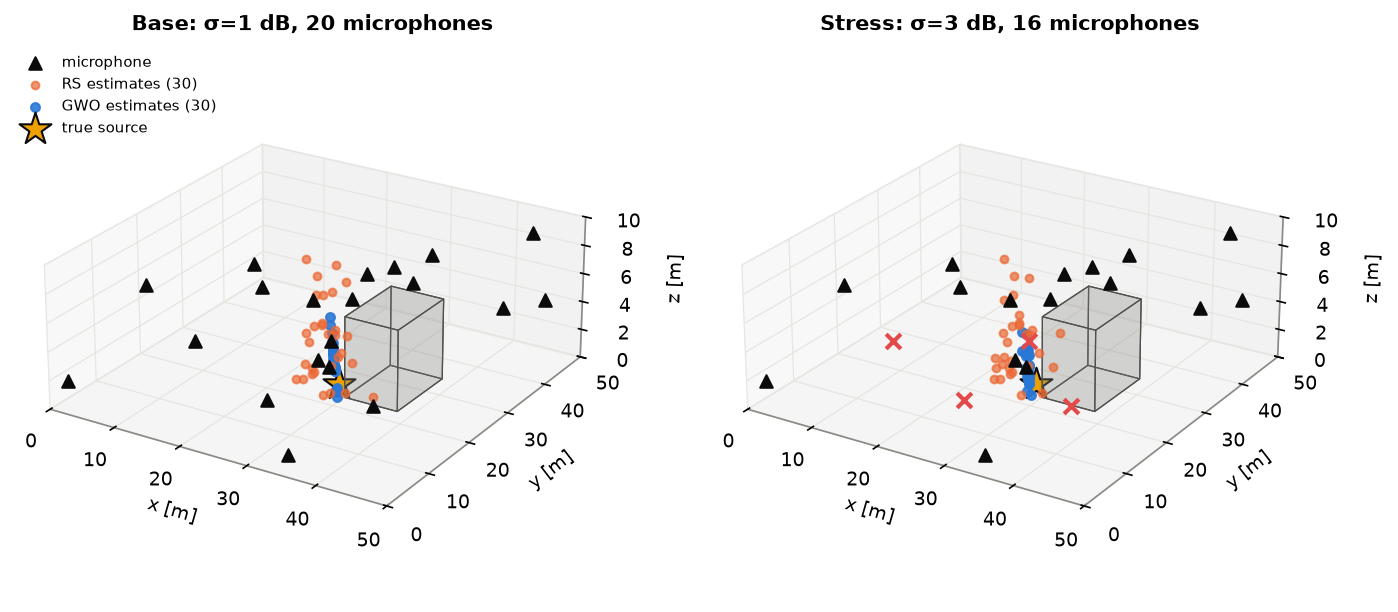

In [16]:
# 8. Fig 1
# ---- Fig 1: 3-D scene ---------------------------------------------------------------------
fig = plt.figure(figsize=(11, 4.8))
for p, (key, title) in enumerate((("base", "Base: σ=1 dB, 20 microphones"),
                                  ("stress", "Stress: σ=3 dB, 16 microphones"))):
    ax = fig.add_subplot(1, 2, p + 1, projection="3d")
    keep = SCEN[key].keep
    M = INST["mics"]
    ax.scatter(*M[keep].T, marker="^", s=36, c=C_INK, label="microphone", depthshade=False)
    if key == "stress":
        ax.scatter(*M[INST["removed"]].T, marker="x", s=50, c="#e34948", label="removed mic",
                   depthshade=False)
    draw_box3d(ax, INST["box_lo"], INST["box_hi"])
    Xr = arrays(STRESS[key]["rs"], SCEN[key])["X"]
    Xg = arrays(STRESS[key]["gwo"], SCEN[key])["X"]
    ax.scatter(*Xr[:, :3].T, s=14, c=C_RS, alpha=0.7, label="RS estimates (30)",
               depthshade=False)
    ax.scatter(*Xg[:, :3].T, s=18, c=C_GWO, alpha=0.9, label="GWO estimates (30)",
               depthshade=False)
    ax.scatter(*INST["s_true"], marker="*", s=260, c="#eda100", edgecolor=C_INK,
               label="true source", depthshade=False)
    ax.set(xlim=(0, 50), ylim=(0, 50), zlim=(0, 10), xlabel="x [m]", ylabel="y [m]",
           zlabel="z [m]", title=title)
    ax.set_box_aspect((5, 5, 2))
    ax.view_init(elev=24, azim=-58)
    if p == 0:
        ax.legend(loc="upper left", fontsize=7, bbox_to_anchor=(-0.05, 1.0))
savefig(fig, "fig01_scene_3d.png")

**Fig. 1 — scene.** Microphones (▲), obstacle (grey box), true source (★), and the 30 final
estimates per method. GWO's estimates form a tight cluster spread mainly **vertically** next to the
source, RS's are scattered over several metres. The vertical spread is a geometry effect: the
microphones span only 10 m in z versus 50 m in x/y, so z is the least observable coordinate (CRB
σ_z = 3.2 m vs σ_x = 0.97 m, σ_y = 0.58 m in the base case). In the stress panel the four removed
microphones (✕) are mostly on the near side of the source, which weakens the range information.

  saved figures/fig02_convergence.png


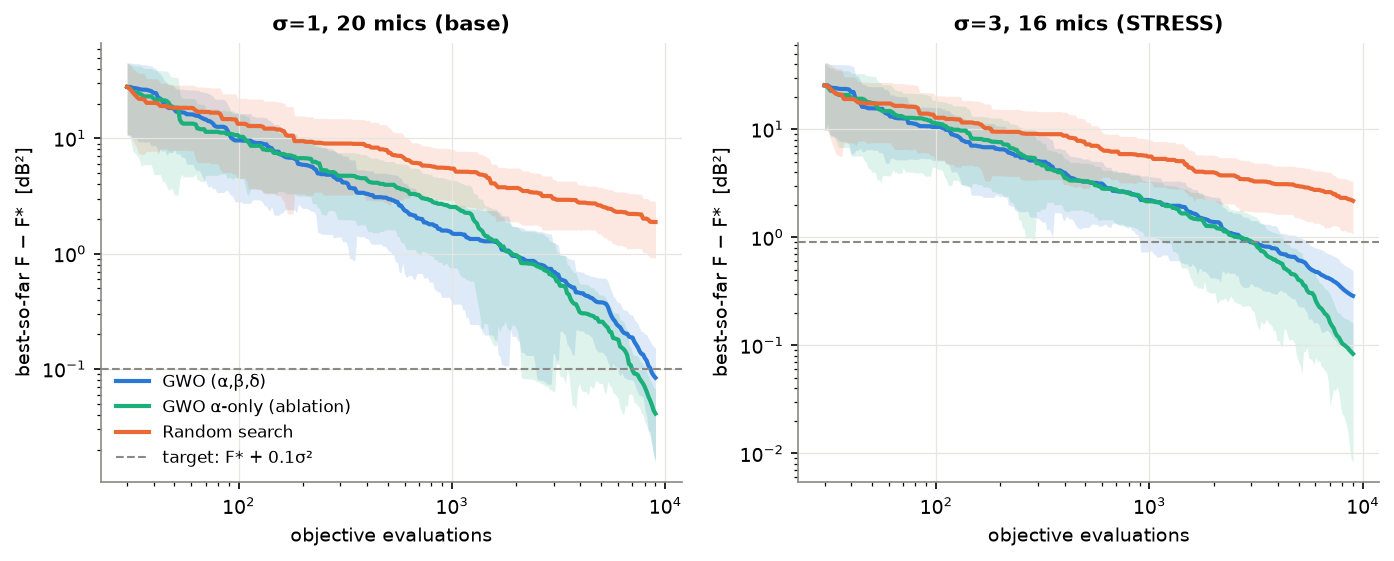

In [17]:
# 8. Fig 2
# ---- Fig 2: convergence, mean ± std best-so-far vs evaluations ------------------------------
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, key in zip(axs, ("base", "stress")):
    for runs, lab, c in ((STRESS[key]["gwo"], "GWO (α,β,δ)", C_GWO),
                         (ABL[key]["alpha"], "GWO α-only (ablation)", C_ALPHA),
                         (STRESS[key]["rs"], "Random search", C_RS)):
        x, m, s = mean_std_curve(runs, offset=REF[key]["F"])
        ax.plot(x, m, color=c, label=lab)
        band(ax, x, m, s, c)
    ax.axhline(0.1 * SCEN[key].sigma ** 2, color=C_MUTED, ls="--", lw=1,
               label="target: F* + 0.1σ²")
    ax.set(xscale="log", yscale="log", xlabel="objective evaluations",
           ylabel="best-so-far F − F*  [dB²]", title=SCEN[key].name)
axs[0].legend(fontsize=8)
savefig(fig, "fig02_convergence.png")

**Fig. 2 — convergence** (mean ± std of best-so-far F − F* per evaluation, log–log; the first 30
evaluations are shared by all methods via common seeds; the lower band edge is floored at mean/10
for the log axis). GWO and RS start from the same 30 points and stay close for the first ~50–100
evaluations (GWO is still effectively random), then GWO's information sharing kicks in and the gap widens by one to two orders of
magnitude. Under stress all curves flatten earlier: the absolute floor F* is ten times higher and
the landscape is smoother, so the *relative* improvement left is smaller. The α-only ablation
tracks the three-leader curve and is slightly lower at the end (greedier exploitation).

  saved figures/fig03_main_boxplots.png


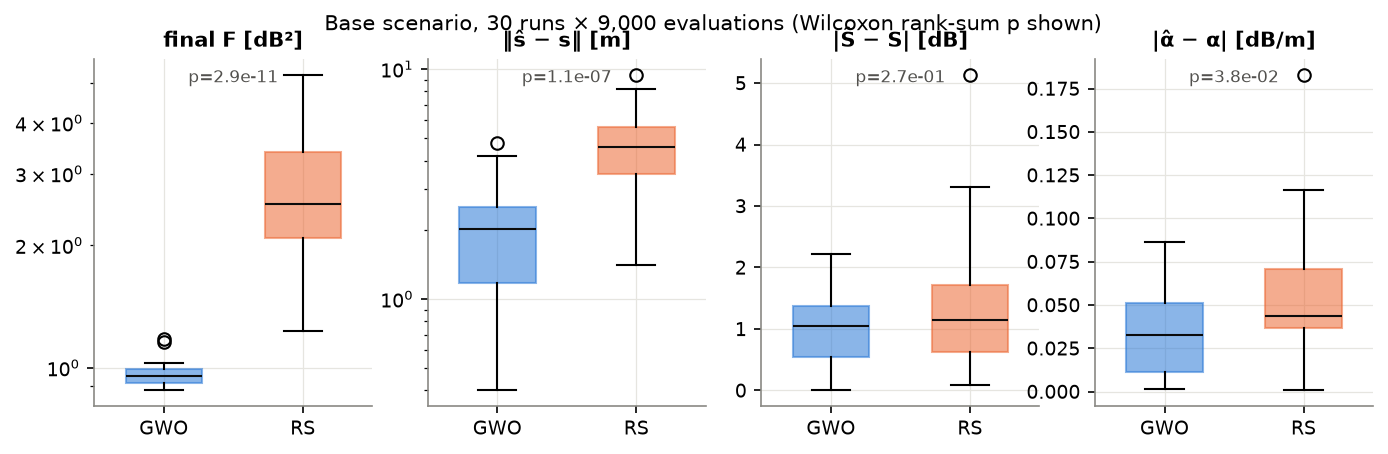

In [18]:
# 8. Fig 3
# ---- Fig 3: main comparison box plots -----------------------------------------------------
fig, axs = plt.subplots(1, 4, figsize=(11, 3.0))
for ax, (k, lab) in zip(axs, (("F", "final F [dB²]"), ("loc", "‖ŝ − s‖ [m]"),
                              ("S", "|Ŝ − S| [dB]"), ("a", "|α̂ − α| [dB/m]"))):
    bp = ax.boxplot([A_g[k], A_r[k]], tick_labels=["GWO", "RS"], patch_artist=True, widths=0.55,
                    medianprops=dict(color=C_INK))
    for patch, c in zip(bp["boxes"], (C_GWO, C_RS)):
        patch.set(facecolor=c, alpha=0.55, edgecolor=c)
    ax.set_title(lab)
    if k in ("F", "loc"):
        ax.set_yscale("log")
    ax.text(0.5, 0.97, f"p={tests[k]['p']:.1e}", transform=ax.transAxes, ha="center",
            va="top", fontsize=8, color="#52514e")
fig.suptitle("Base scenario, 30 runs × 9,000 evaluations (Wilcoxon rank-sum p shown)",
             fontsize=10)
savefig(fig, "fig03_main_boxplots.png")

**Fig. 3 — final quality, base scenario.** GWO dominates RS on F and localisation (p ≤ 10⁻⁷); for
the source level the boxes overlap (p = 0.27) because S is the parameter most strongly coupled to
α and range — fitting the data better does not pin S down.

  saved figures/fig04_sensitivity_box_base.png
  saved figures/fig05_sensitivity_conv_base.png
  saved figures/fig04_sensitivity_box_stress.png
  saved figures/fig05_sensitivity_conv_stress.png


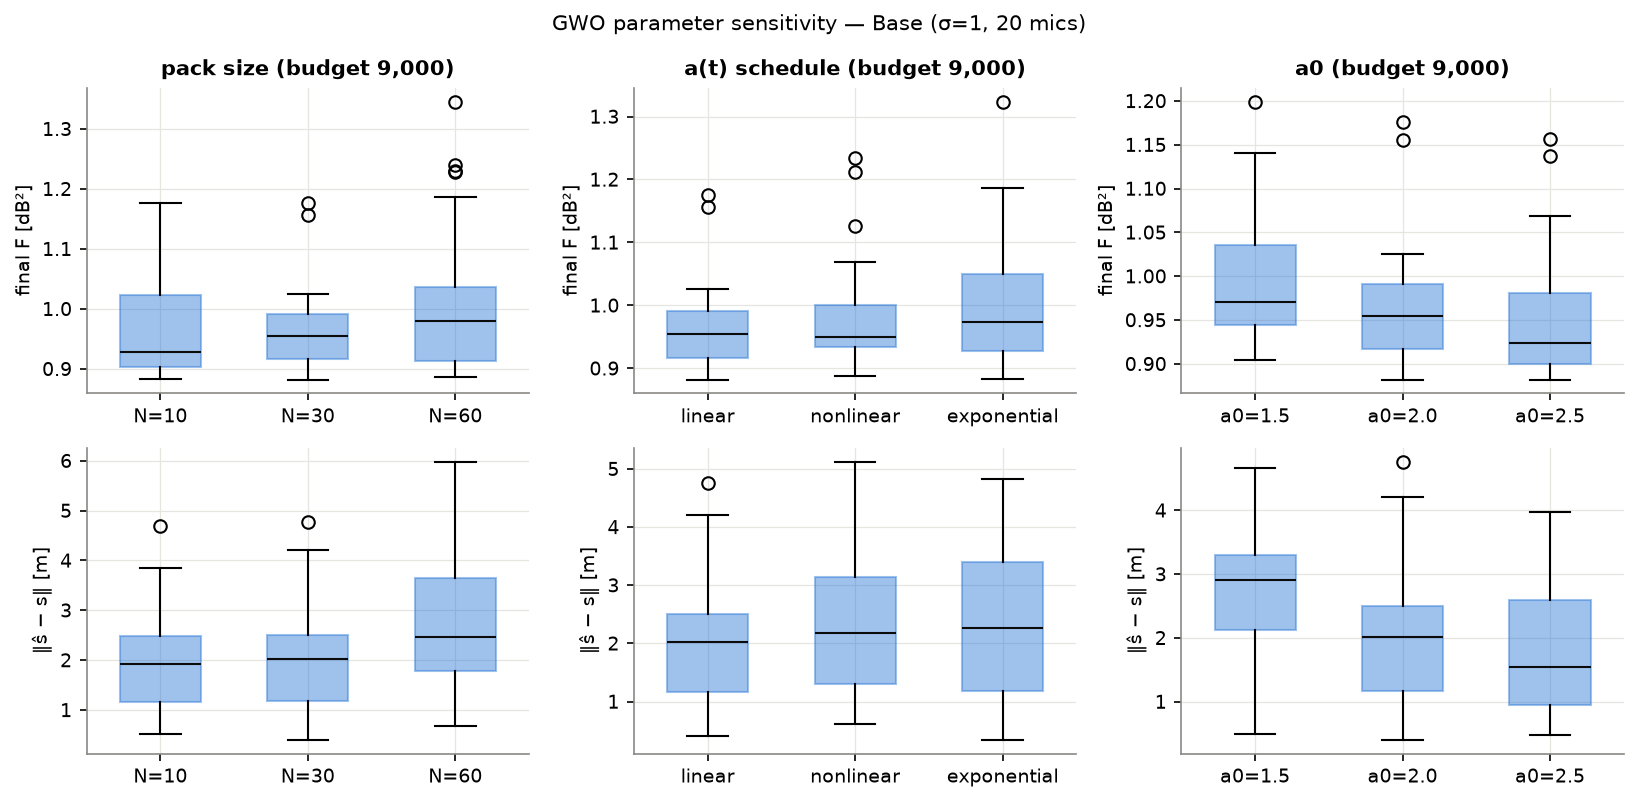

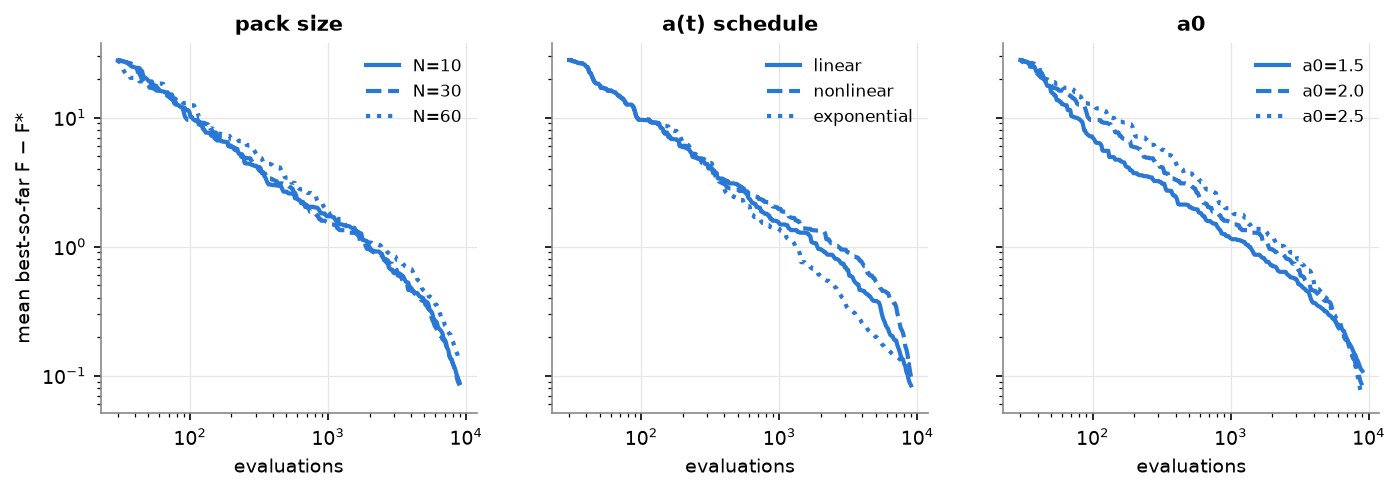

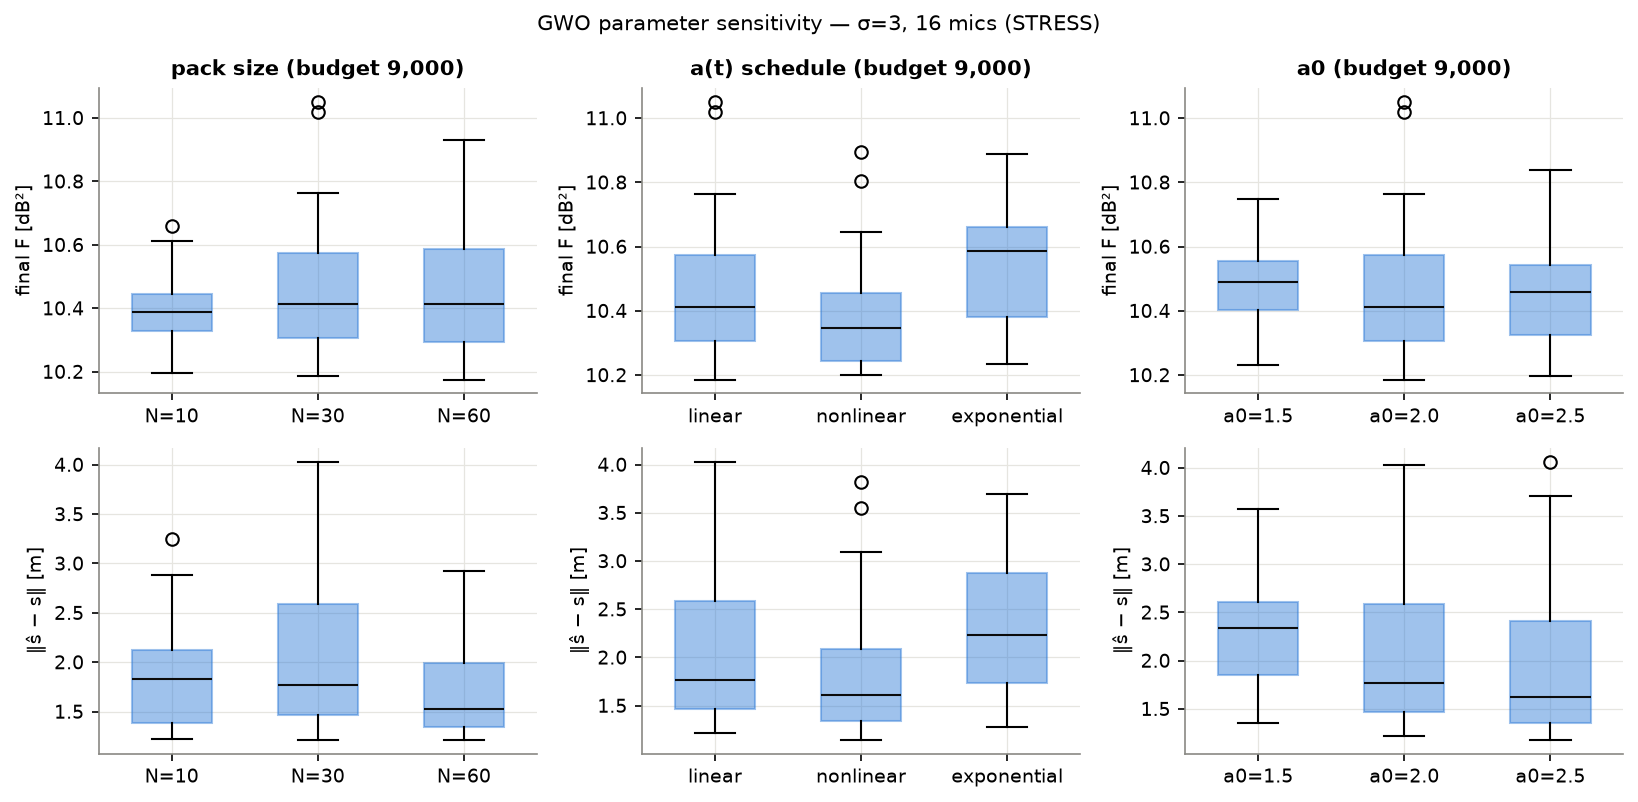

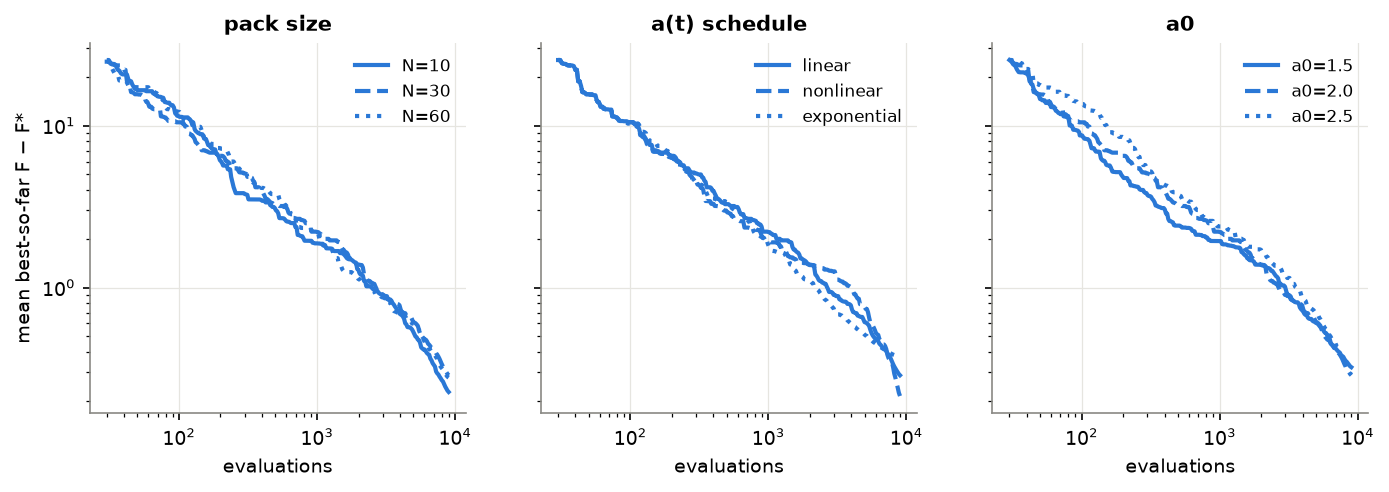

In [19]:
# 8. Fig 4 + 5
# ---- Fig 4 + 5: sensitivity box plots and convergence -------------------------------------
def sens_figs(store, prob, ref, tag):
    groups = ["pack size", "a(t) schedule", "a0"]
    fig, axs = plt.subplots(2, 3, figsize=(11, 5.4))
    for j, g in enumerate(groups):
        items = [(lab, runs) for (gg, lab), runs in store.items() if gg == g]
        for row, (k, ylab) in enumerate((("F", "final F [dB²]"), ("loc", "‖ŝ − s‖ [m]"))):
            ax = axs[row, j]
            data = [arrays(runs, prob)[k] for _, runs in items]
            bp = ax.boxplot(data, tick_labels=[lab for lab, _ in items], patch_artist=True,
                            widths=0.55, medianprops=dict(color=C_INK))
            for patch in bp["boxes"]:
                patch.set(facecolor=C_GWO, alpha=0.45, edgecolor=C_GWO)
            ax.set_ylabel(ylab)
            if row == 0:
                ax.set_title(f"{g} (budget {BUDGET:,})")
    fig.suptitle(f"GWO parameter sensitivity — {prob.name}", fontsize=10)
    fig.tight_layout()
    savefig(fig, f"fig04_sensitivity_box_{tag}.png")

    fig, axs = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
    for ax, g in zip(axs, groups):
        items = [(lab, runs) for (gg, lab), runs in store.items() if gg == g]
        # three settings of ONE method: same hue, different line styles
        for (lab, runs), ls in zip(items, ("-", "--", ":")):
            x, m, s = mean_std_curve(runs, offset=ref["F"])
            ax.plot(x, m, color=C_GWO, ls=ls, label=lab)
        ax.set(xscale="log", yscale="log", xlabel="evaluations", title=g)
        ax.legend(fontsize=8)
    axs[0].set_ylabel("mean best-so-far F − F*")
    savefig(fig, f"fig05_sensitivity_conv_{tag}.png")


sens_figs(sens_runs, BASE, REF["base"], "base")
sens_figs(sens_runs_stress, SCEN["stress"], REF["stress"], "stress")

**Figs. 4–5 — sensitivity** (box plots of final F and error; mean convergence F − F* per setting;
base and stress). Same budget for every box. Main effects: N = 60 is too few iterations at σ = 1;
the exponential schedule converges fastest early but stalls (its curve flattens first: a(t) < 1
after ≈ 40 iterations); a0 = 1.5 under-explores; a0 = 2.5 and the nonlinear schedule — both of
which extend the |A| > 1 phase — give the best final quality on this coupled landscape.

  saved figures/fig06_leader_pack_trajectory.png


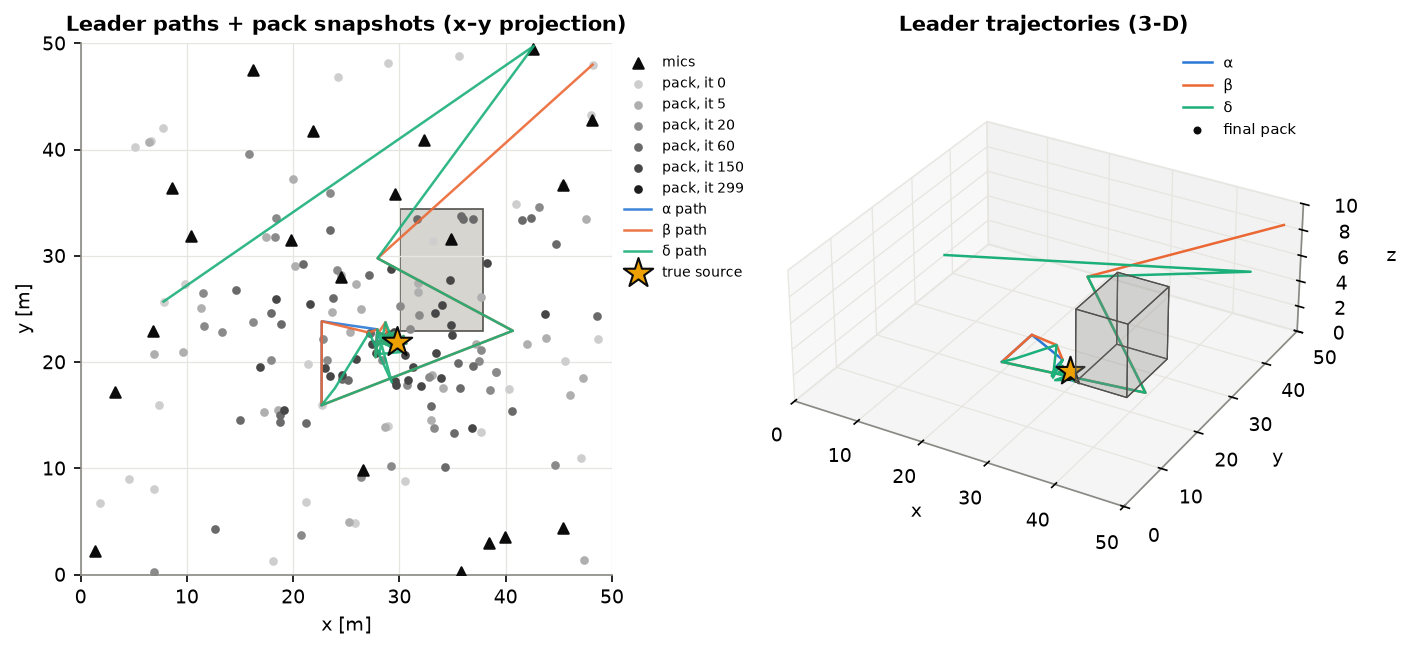

In [20]:
# 8. Fig 6
# ---- Fig 6: leader and pack trajectory (representative run, seed 4612 + 0) ----------------
rep = gwo(BASE, np.random.default_rng(SEED), record_pack=True)   # identical to run k=0
L = rep["hist"]["leaders"]
P = rep["pack"]
fig = plt.figure(figsize=(11, 4.6))
ax = fig.add_subplot(1, 2, 1)
draw_rect(ax, INST["box_lo"], INST["box_hi"])
ax.scatter(*BASE.mics[:, :2].T, marker="^", c=C_INK, s=25, label="mics", zorder=3)
snaps = [0, 5, 20, 60, 150, len(P) - 1]
greys = plt.cm.Greys(np.linspace(0.3, 0.9, len(snaps)))
for t, g in zip(snaps, greys):
    ax.scatter(*P[t][:, :2].T, s=10, color=g, zorder=2, label=f"pack, it {t}")
for i, (nm, c) in enumerate((("α", C_GWO), ("β", C_RS), ("δ", C_ALPHA))):
    ax.plot(L[:, i, 0], L[:, i, 1], color=c, lw=1.2, alpha=0.9, label=f"{nm} path", zorder=4)
ax.scatter(*INST["s_true"][:2], marker="*", s=220, c="#eda100", edgecolor=C_INK, zorder=5,
           label="true source")
ax.set(xlim=(0, 50), ylim=(0, 50), xlabel="x [m]", ylabel="y [m]", aspect="equal",
       title="Leader paths + pack snapshots (x–y projection)")
ax.legend(fontsize=6.5, loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax = fig.add_subplot(1, 2, 2, projection="3d")
draw_box3d(ax, INST["box_lo"], INST["box_hi"])
for i, (nm, c) in enumerate((("α", C_GWO), ("β", C_RS), ("δ", C_ALPHA))):
    ax.plot(*L[:, i, :3].T, color=c, lw=1.2, label=nm)
ax.scatter(*P[-1][:, :3].T, s=8, c=C_INK, depthshade=False, label="final pack")
ax.scatter(*INST["s_true"], marker="*", s=200, c="#eda100", edgecolor=C_INK, depthshade=False)
ax.set(xlim=(0, 50), ylim=(0, 50), zlim=(0, 10), xlabel="x", ylabel="y", zlabel="z",
       title="Leader trajectories (3-D)")
ax.set_box_aspect((5, 5, 2))
ax.legend(fontsize=7)
savefig(fig, "fig06_leader_pack_trajectory.png")

**Fig. 6 — leader and pack trajectories** (run k = 0). Early leader paths make long jumps across
the room (a leader is replaced by a better wolf found far away — exploration). After ≈ 60
iterations the paths shrink to short moves near the source and the pack snapshots (light → dark)
contract from the uniform cloud to a tight group; β and δ trail α, so the averaged guidance keeps
the pack slightly spread around α instead of on top of it. The leaders do pass across the
obstacle footprint — the graded penalty allows this — but end on the free side.

  saved figures/fig07_a_A_diversity.png


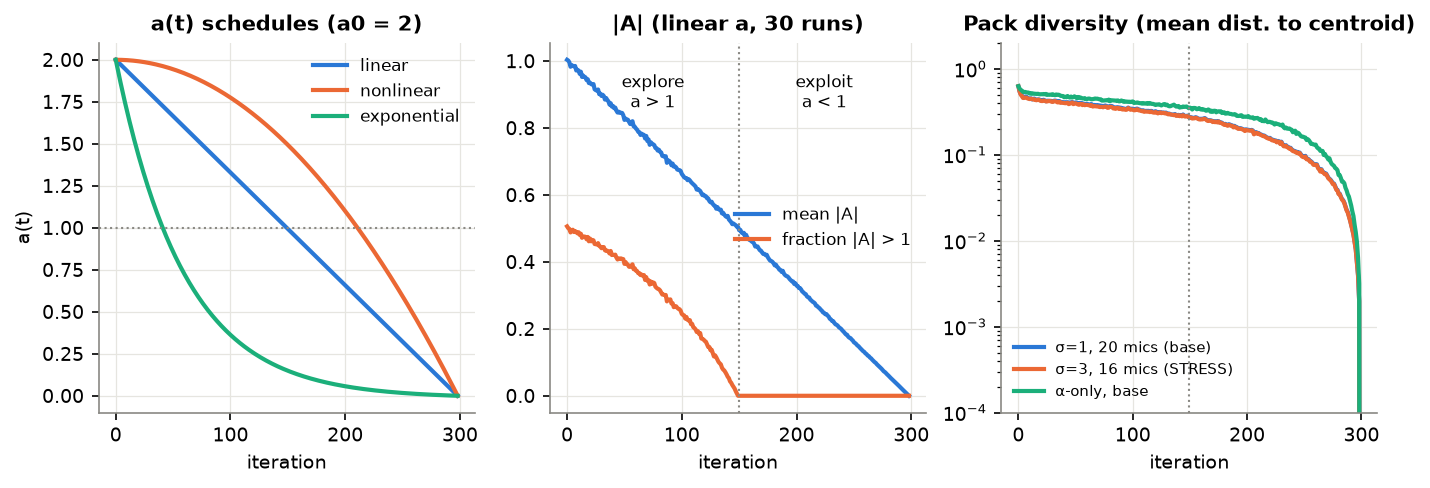

In [21]:
# 8. Fig 7
# ---- Fig 7: a(t), |A| and pack diversity (exploration -> exploitation) -----------------------
fig, axs = plt.subplots(1, 3, figsize=(11, 3.2))
it = np.arange(len(rep["hist"]["a"]))
ax = axs[0]
for s, c in zip(("linear", "nonlinear", "exponential"), (C_GWO, C_RS, C_ALPHA)):
    ax.plot(it, [a_schedule(t, len(it), 2.0, s) for t in it], color=c, label=s)
ax.axhline(1, color=C_MUTED, ls=":", lw=1)
ax.set(xlabel="iteration", ylabel="a(t)", title="a(t) schedules (a0 = 2)")
ax.legend(fontsize=8)
ax = axs[1]
H = [r["hist"] for r in STRESS["base"]["gwo"]]
ax.plot(it, np.mean([h["Aabs"] for h in H], 0), color=C_GWO, label="mean |A|")
ax.plot(it, np.mean([h["Afrac"] for h in H], 0), color=C_RS, label="fraction |A| > 1")
ax.axvline(len(it) / 2, color=C_MUTED, ls=":", lw=1)
ax.text(len(it) * 0.25, 0.92, "explore\na > 1", ha="center", va="top", fontsize=8,
        transform=ax.get_xaxis_transform())
ax.text(len(it) * 0.75, 0.92, "exploit\na < 1", ha="center", va="top", fontsize=8,
        transform=ax.get_xaxis_transform())
ax.set(xlabel="iteration", title="|A| (linear a, 30 runs)")
ax.legend(fontsize=8, loc="center right")
ax = axs[2]
for key, c in (("base", C_GWO), ("stress", C_RS)):
    D = np.array([r["hist"]["div"] for r in STRESS[key]["gwo"]])
    ax.plot(np.arange(D.shape[1]), D.mean(0), color=c, label=SCEN[key].name)
D = np.array([r["hist"]["div"] for r in ABL["base"]["alpha"]])
ax.plot(np.arange(D.shape[1]), D.mean(0), color=C_ALPHA, label="α-only, base")
ax.axvline(len(it) / 2, color=C_MUTED, ls=":", lw=1)
ax.set(yscale="log", ylim=(1e-4, 2), xlabel="iteration",
       title="Pack diversity (mean dist. to centroid)")
ax.legend(fontsize=7)
savefig(fig, "fig07_a_A_diversity.png")

**Fig. 7 — exploration vs exploitation.** Left: the three a(t) schedules; a = 1 (dotted) is the
switch point. Middle: mean |A| decays with a; the fraction of moves with |A| > 1 starts at 50 % and
reaches **zero exactly when a(t) crosses 1** (iteration 150 for linear) — after that every move
lands between the wolf and its leader. Right: pack diversity decays slowly during the |A| > 1 phase
and accelerates in the exploitation phase; it collapses only in the last few iterations as a → 0.
The stress pack keeps slightly *less* diversity — a smoother landscape gives more coherent leaders.

  saved figures/fig08_leader_consensus.png


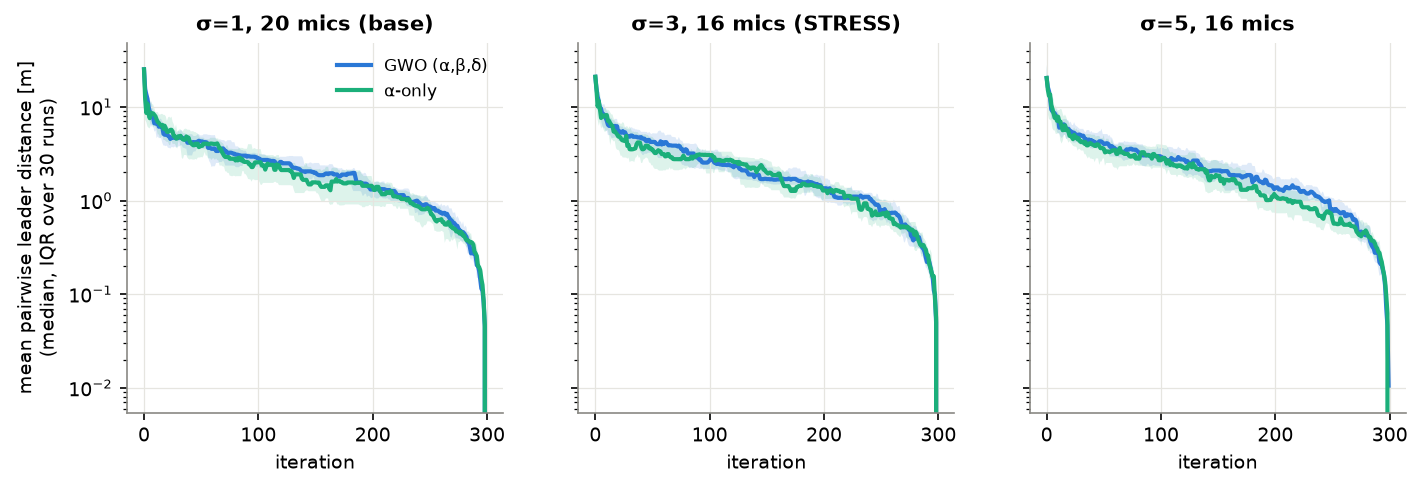

In [22]:
# 8. Fig 8
# ---- Fig 8: leader diversity / consensus ---------------------------------------------------
fig, axs = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for ax, key in zip(axs, ("base", "stress", "extreme")):
    for g, lab, c in (("three", "GWO (α,β,δ)", C_GWO), ("alpha", "α-only", C_ALPHA)):
        cons = leader_stats(ABL[key][g], REF[key]["x"])["consensus"].mean(2)   # runs x T
        med = np.median(cons, 0)
        q1, q3 = np.percentile(cons, [25, 75], axis=0)
        ax.plot(np.arange(len(med)), med, color=c, label=lab)
        ax.fill_between(np.arange(len(med)), q1, q3, color=c, alpha=0.15, lw=0)
    ax.set(yscale="log", xlabel="iteration", title=SCEN[key].name)
axs[0].set_ylabel("mean pairwise leader distance [m]\n(median, IQR over 30 runs)")
axs[0].legend(fontsize=8)
savefig(fig, "fig08_leader_consensus.png")

**Fig. 8 — leader diversity / consensus** (mean pairwise distance between α, β, δ; median and IQR
over 30 runs). The leaders start ~20 m apart, agree to within a few metres after ≈ 30 iterations
and to < 1 m only after ≈ 250 iterations: there is **no premature consensus** — the three leaders
remain distinct candidates throughout the exploration phase, so no single noisy candidate dictates
the pack early. With higher noise the leaders stay apart longer (flatter valley → more
near-equivalent candidates). α-only shows a similar curve because β and δ are still recorded,
but they do not influence its pack.

  saved figures/fig09_stress_boxplots.png


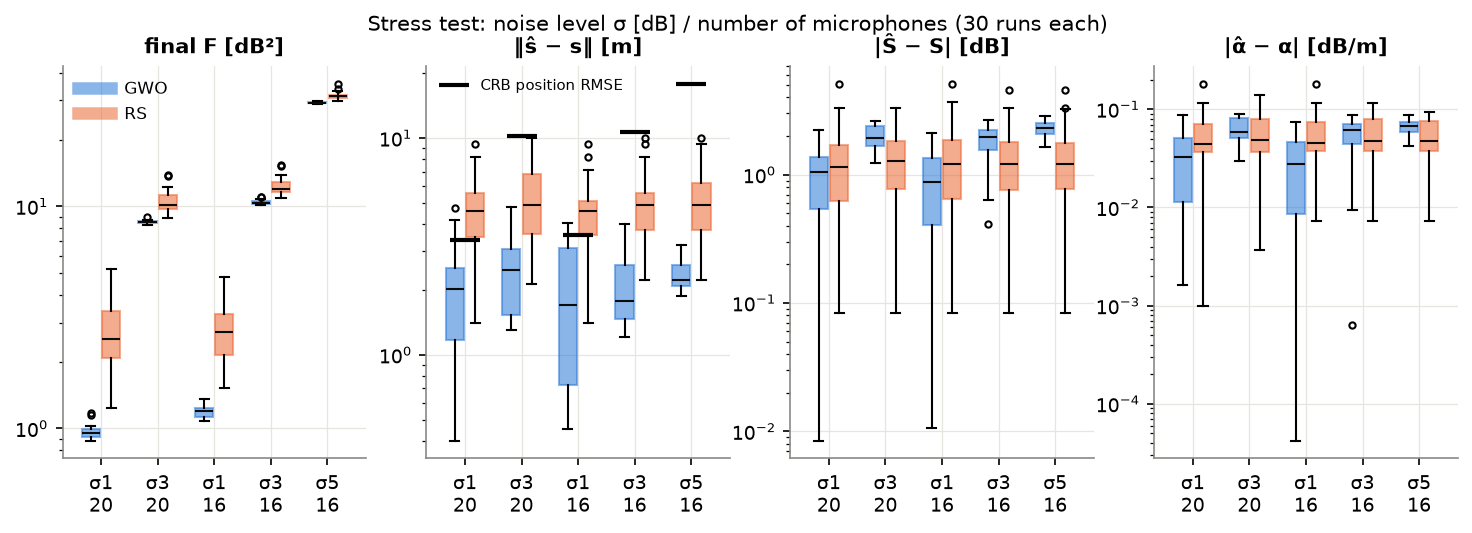

In [23]:
# 8. Fig 9
# ---- Fig 9: stress test summary ------------------------------------------------------------
keys = list(SCEN)
fig, axs = plt.subplots(1, 4, figsize=(12, 3.4))
for ax, (k, lab) in zip(axs, (("F", "final F [dB²]"), ("loc", "‖ŝ − s‖ [m]"),
                              ("S", "|Ŝ − S| [dB]"), ("a", "|α̂ − α| [dB/m]"))):
    pos = np.arange(len(keys))
    for off, m, c in ((-0.18, "gwo", C_GWO), (0.18, "rs", C_RS)):
        data = [arrays(STRESS[kk][m], SCEN[kk])[k] for kk in keys]
        bp = ax.boxplot(data, positions=pos + off, widths=0.32, patch_artist=True,
                        medianprops=dict(color=C_INK), flierprops=dict(markersize=3))
        for patch in bp["boxes"]:
            patch.set(facecolor=c, alpha=0.55, edgecolor=c)
    if k == "loc":
        ax.plot(pos, [crb(SCEN[kk])["pos_rmse"] for kk in keys], "k_", ms=14, mew=2,
                label="CRB position RMSE")
        ax.legend(fontsize=7, loc="upper left")
    ax.set_xticks(pos, ["σ1\n20", "σ3\n20", "σ1\n16", "σ3\n16", "σ5\n16"])
    ax.set_title(lab)
    ax.set_yscale("log")
axs[0].plot([], [], color=C_GWO, lw=6, alpha=0.55, label="GWO")
axs[0].plot([], [], color=C_RS, lw=6, alpha=0.55, label="RS")
axs[0].legend(fontsize=8)
fig.suptitle("Stress test: noise level σ [dB] / number of microphones (30 runs each)",
             fontsize=10)
savefig(fig, "fig09_stress_boxplots.png")

**Fig. 9 — stress test on the fixed data set.** F rises with σ² for both methods; GWO's spread
stays tiny. Localisation of GWO stays ≈ 2 m (this noise pattern moves x_ML little), but its |Ŝ − S|
and |α̂ − α| clearly grow with σ: the ML solution moves along the S–α valley (α → 0, S ↓).
The black bars show the CRB RMSE: noise, not microphone count, drives it.

  saved figures/fig10_ablation_estimates.png


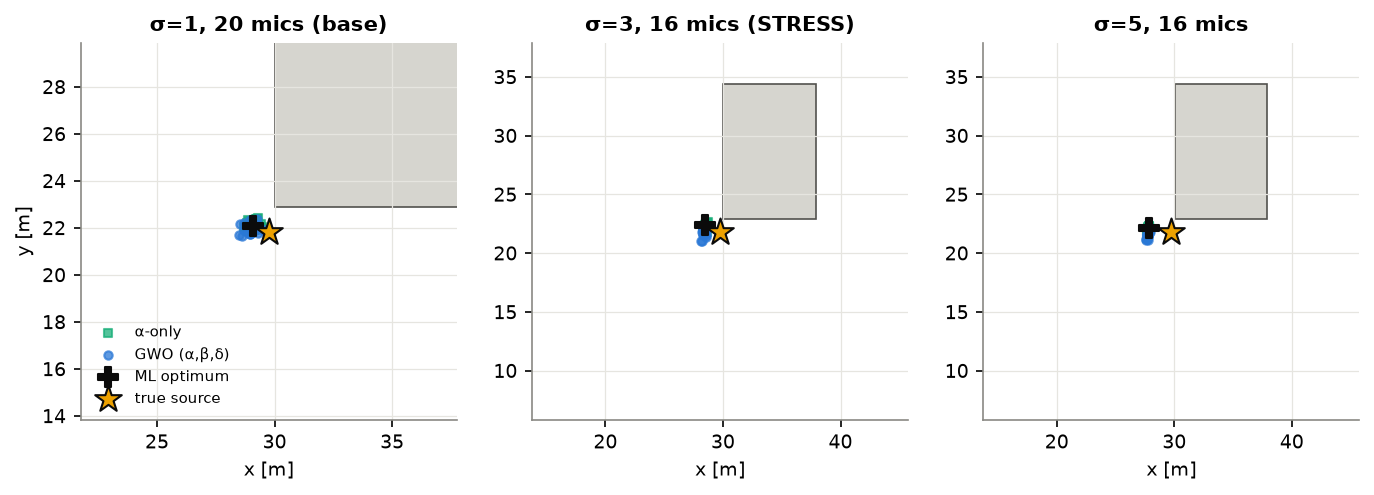

In [24]:
# 8. Fig 10
# ---- Fig 10: ablation — final estimates and spread ------------------------------------------
fig, axs = plt.subplots(1, 3, figsize=(11, 3.7))
for ax, key in zip(axs, ("base", "stress", "extreme")):
    draw_rect(ax, INST["box_lo"], INST["box_hi"])
    for g, lab, c, mk in (("alpha", "α-only", C_ALPHA, "s"), ("three", "GWO (α,β,δ)", C_GWO, "o")):
        X = arrays(ABL[key][g], SCEN[key])["X"]
        ax.scatter(X[:, 0], X[:, 1], s=16, c=c, marker=mk, alpha=0.75, label=lab, zorder=3)
    ax.scatter(*REF[key]["x"][:2], marker="P", s=90, c=C_INK, label="ML optimum", zorder=4)
    ax.scatter(*INST["s_true"][:2], marker="*", s=180, c="#eda100", edgecolor=C_INK, zorder=5,
               label="true source")
    s = INST["s_true"]
    w = 8 if key == "base" else 16
    ax.set(xlim=(s[0] - w, s[0] + w), ylim=(s[1] - w, s[1] + w), aspect="equal",
           xlabel="x [m]", title=SCEN[key].name)
axs[0].set_ylabel("y [m]")
axs[0].legend(fontsize=7, loc="lower left")
savefig(fig, "fig10_ablation_estimates.png")

**Fig. 10 — ablation, final estimates (x–y).** Both variants cluster around x_ML (✚), which is
offset from the true source (★) by the noise; the α-only cluster is tighter on this instance
(position spread 0.90 vs 1.19 m under stress), consistent with its greedier exploitation.

  saved figures/fig11_landscape_coupling.png


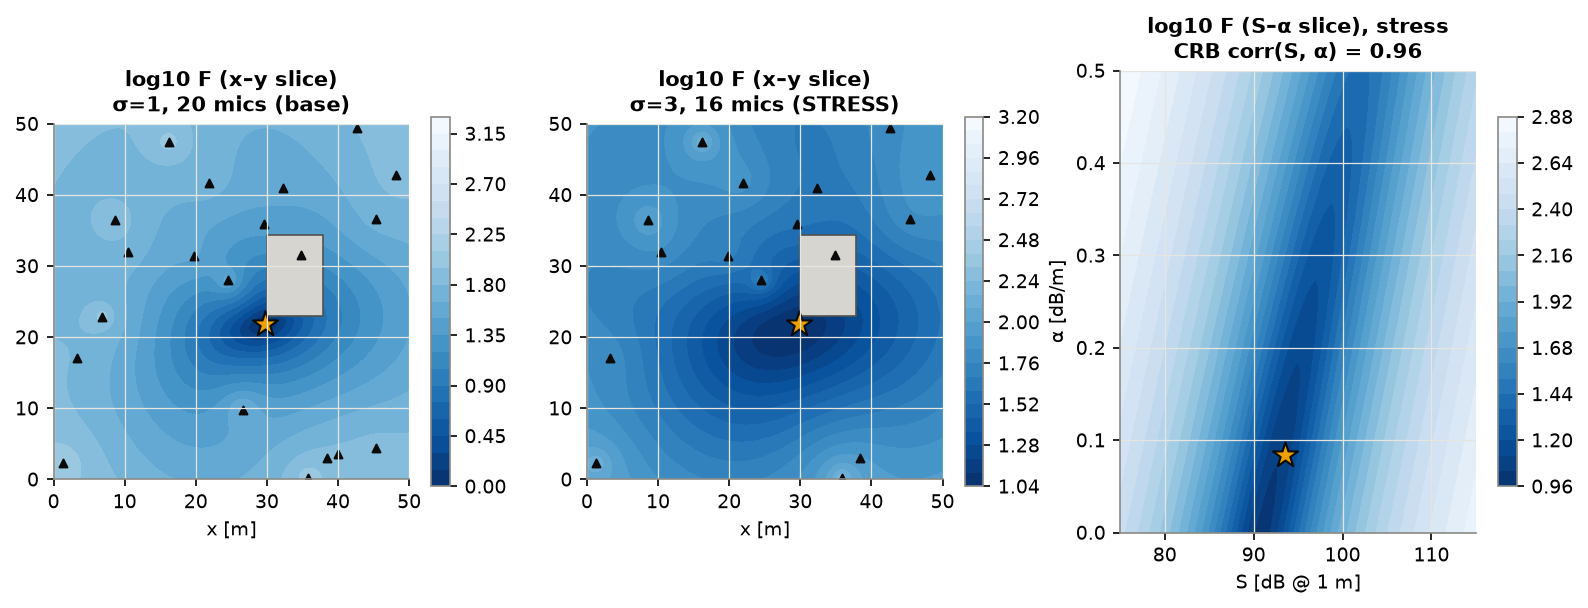

In [25]:
# 8. Fig 11
# ---- Fig 11: landscape slices (observability and S–α–distance coupling) --------------------
fig, axs = plt.subplots(1, 3, figsize=(13, 4.0))
xt = INST["x_true"]
gx = np.linspace(0, 50, 201)
GX, GY = np.meshgrid(gx, gx)
Xg = np.tile(xt, (GX.size, 1))
Xg[:, 0], Xg[:, 1] = GX.ravel(), GY.ravel()
for ax, key in zip(axs[:2], ("base", "stress")):
    Z = SCEN[key].F(Xg).reshape(GX.shape)
    cs = ax.contourf(GX, GY, np.log10(Z), levels=30, cmap="Blues_r")
    draw_rect(ax, INST["box_lo"], INST["box_hi"])
    ax.scatter(*SCEN[key].mics[:, :2].T, marker="^", c=C_INK, s=14)
    ax.scatter(*xt[:2], marker="*", s=160, c="#eda100", edgecolor=C_INK)
    ax.set(aspect="equal", xlabel="x [m]", title=f"log10 F (x–y slice)\n{SCEN[key].name}")
    fig.colorbar(cs, ax=ax, shrink=0.8)
# S–alpha coupling: profile over (S, alpha) after re-optimising position is costly, so we
# show the slice through the ML position and the CRB correlation.
gS = np.linspace(75, 115, 161)
ga = np.linspace(0.0, 0.5, 161)
GS, GA = np.meshgrid(gS, ga)
Xs = np.tile(REF["stress"]["x"], (GS.size, 1))
Xs[:, 3], Xs[:, 4] = GS.ravel(), GA.ravel()
Z = SCEN["stress"].F(Xs).reshape(GS.shape)
cs = axs[2].contourf(GS, GA, np.log10(Z), levels=30, cmap="Blues_r")
axs[2].scatter(INST["S_true"], INST["a_true"], marker="*", s=160, c="#eda100", edgecolor=C_INK)
axs[2].set(xlabel="S [dB @ 1 m]", ylabel="α [dB/m]",
           title=f"log10 F (S–α slice), stress\nCRB corr(S, α) = {crb(SCEN['stress'])['corr'][3, 4]:.2f}")
fig.colorbar(cs, ax=axs[2], shrink=0.8)
savefig(fig, "fig11_landscape_coupling.png")

**Fig. 11 — landscape and coupling.** The x–y slice (at true z, S, α) has a single broad basin
around the source; under stress it becomes wider and shallower (higher floor, smaller relative
contrast) — the observability loss. The S–α slice shows a long diagonal valley: raising S can be
compensated by raising α, so the data constrain only a combination of them (CRB corr = 0.96). This
is the S–α–distance ambiguity that limits parameter accuracy.

  saved figures/fig12_speed_robustness.png


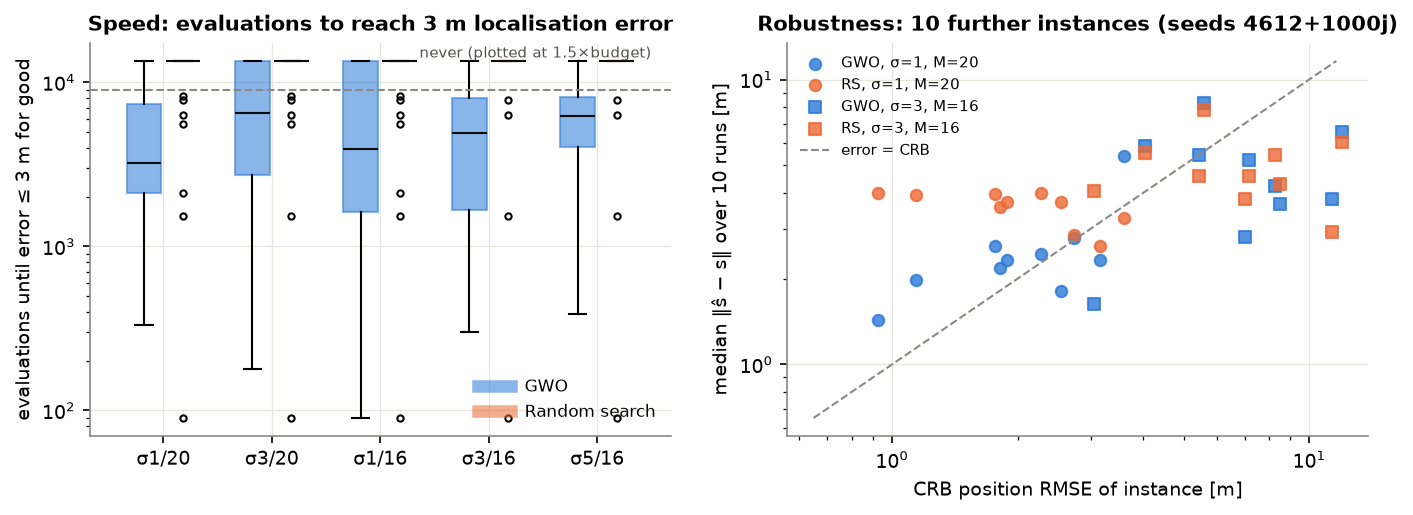

In [26]:
# 8. Fig 12
# ---- Fig 12: time-to-target + robustness across instances -----------------------------------
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
ax = axs[0]
for m, lab, c in (("gwo", "GWO", C_GWO), ("rs", "Random search", C_RS)):
    vals = []
    for kk in keys:
        e_all = np.array([settle_evals(r, INST["s_true"]) for r in STRESS[kk][m]], dtype=float)
        vals.append(np.where(np.isnan(e_all), BUDGET * 1.5, e_all))
    pos = np.arange(len(keys)) + (-0.18 if m == "gwo" else 0.18)
    bp = ax.boxplot(vals, positions=pos, widths=0.32, patch_artist=True,
                    medianprops=dict(color=C_INK), flierprops=dict(markersize=3))
    for patch in bp["boxes"]:
        patch.set(facecolor=c, alpha=0.55, edgecolor=c)
    ax.plot([], [], color=c, lw=6, alpha=0.55, label=lab)
ax.axhline(BUDGET, color=C_MUTED, ls="--", lw=1)
ax.text(len(keys) - 0.5, BUDGET * 1.5, "never (plotted at 1.5×budget)", ha="right",
        va="bottom", fontsize=7, color="#52514e")
ax.set_xticks(np.arange(len(keys)), ["σ1/20", "σ3/20", "σ1/16", "σ3/16", "σ5/16"])
ax.set(yscale="log", ylabel=f"evaluations until error ≤ {LOC_TARGET:g} m for good",
       title=f"Speed: evaluations to reach {LOC_TARGET:g} m localisation error")
ax.legend(fontsize=8, loc="lower right")
ax = axs[1]
for (sc, m), c, mk in ((("σ=1, M=20", "gwo"), C_GWO, "o"), (("σ=1, M=20", "rs"), C_RS, "o"),
                       (("σ=3, M=16", "gwo"), C_GWO, "s"), (("σ=3, M=16", "rs"), C_RS, "s")):
    d = rob_tab[(rob_tab.scenario == sc) & (rob_tab.method == m)]
    ax.scatter(d.crb_pos_rmse, d.loc_median, c=c, marker=mk, s=30, alpha=0.8,
               label=f"{'GWO' if m == 'gwo' else 'RS'}, {sc}")
lim = [rob_tab.crb_pos_rmse.min() * 0.7, rob_tab.loc_median.max() * 1.4]
ax.plot(lim, lim, color=C_MUTED, ls="--", lw=1, label="error = CRB")
ax.set(xscale="log", yscale="log", xlabel="CRB position RMSE of instance [m]",
       ylabel="median ‖ŝ − s‖ over 10 runs [m]",
       title="Robustness: 10 further instances (seeds 4612+1000j)")
ax.legend(fontsize=7)
savefig(fig, "fig12_speed_robustness.png")

**Fig. 12 — speed and robustness.** Left: evaluations after which the incumbent stays within
3 m of the truth. GWO gets there in 87 % of the base runs (median 2,775 evaluations) and 93 % under
stress (median 4,350); RS only in 13–23 % of runs (most boxes sit at "never"). Higher noise delays
the moment the incumbent settles. Right: across 10 further instances, each instance's median error
versus its CRB; at σ = 1 GWO (blue ●) stays close to the CRB line (within ≈ 1.5×) and below RS on
9/10 instances, while at stress
(■) both methods cluster together — the noise floor, not the optimiser, sets the error.

  saved figures/fig14_stress_noise_mc.png


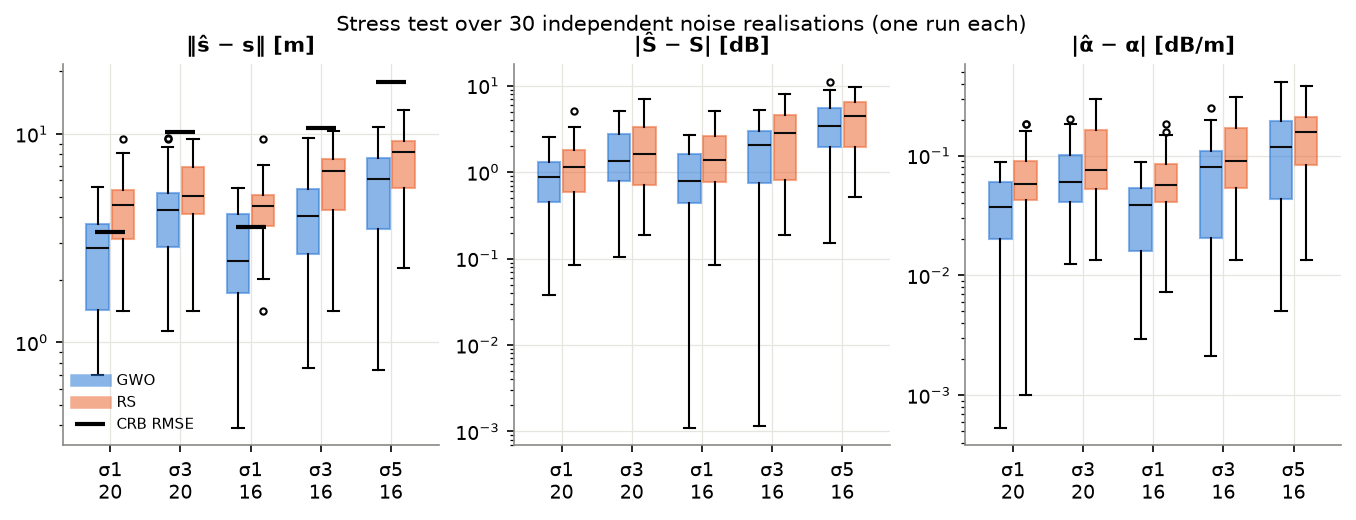

In [27]:
# 8. Fig 14
# ---- Fig 14: stress test over noise realisations ----------------------------------------
fig, axs = plt.subplots(1, 3, figsize=(11, 3.3))
for ax, (col, lab) in zip(axs, ((0, "‖ŝ − s‖ [m]"), (1, "|Ŝ − S| [dB]"), (2, "|α̂ − α| [dB/m]"))):
    pos = np.arange(len(keys))
    for off, m, c in ((-0.18, "gwo", C_GWO), (0.18, "rs", C_RS)):
        bp = ax.boxplot([MC[kk][m][:, col] for kk in keys], positions=pos + off, widths=0.32,
                        patch_artist=True, medianprops=dict(color=C_INK),
                        flierprops=dict(markersize=3))
        for patch in bp["boxes"]:
            patch.set(facecolor=c, alpha=0.55, edgecolor=c)
        ax.plot([], [], color=c, lw=6, alpha=0.55, label="GWO" if m == "gwo" else "RS")
    if col == 0:
        ax.plot(pos, [crb(SCEN[kk])["pos_rmse"] for kk in keys], "k_", ms=14, mew=2,
                label="CRB RMSE")
    ax.set_xticks(pos, ["σ1\n20", "σ3\n20", "σ1\n16", "σ3\n16", "σ5\n16"])
    ax.set(title=lab, yscale="log")
axs[0].legend(fontsize=7)
fig.suptitle("Stress test over 30 independent noise realisations (one run each)", fontsize=10)
savefig(fig, "fig14_stress_noise_mc.png")

**Fig. 14 — stress over 30 noise realisations.** The honest statistical picture: every error grows
with σ; dropping 4 microphones changes little at fixed σ. GWO's advantage over RS shrinks from
~40 % (σ = 1) to ~16 % (σ = 5) in RMSE, because the achievable accuracy degrades for any estimator.

instance 5612: true [32.59 26.86  1.46 98.46  0.19]  ML [36.66 21.62  4.49 96.99  0.1 ] F*=8.81; GWO F range [8.82, 10.12]
instance 13612: true [43.14 37.41  3.06 89.63  0.11]  ML [36.64 35.37  6.57 92.29  0.32] F*=5.43; GWO F range [5.45, 10.42]
  saved figures/fig15_failure_cases.png


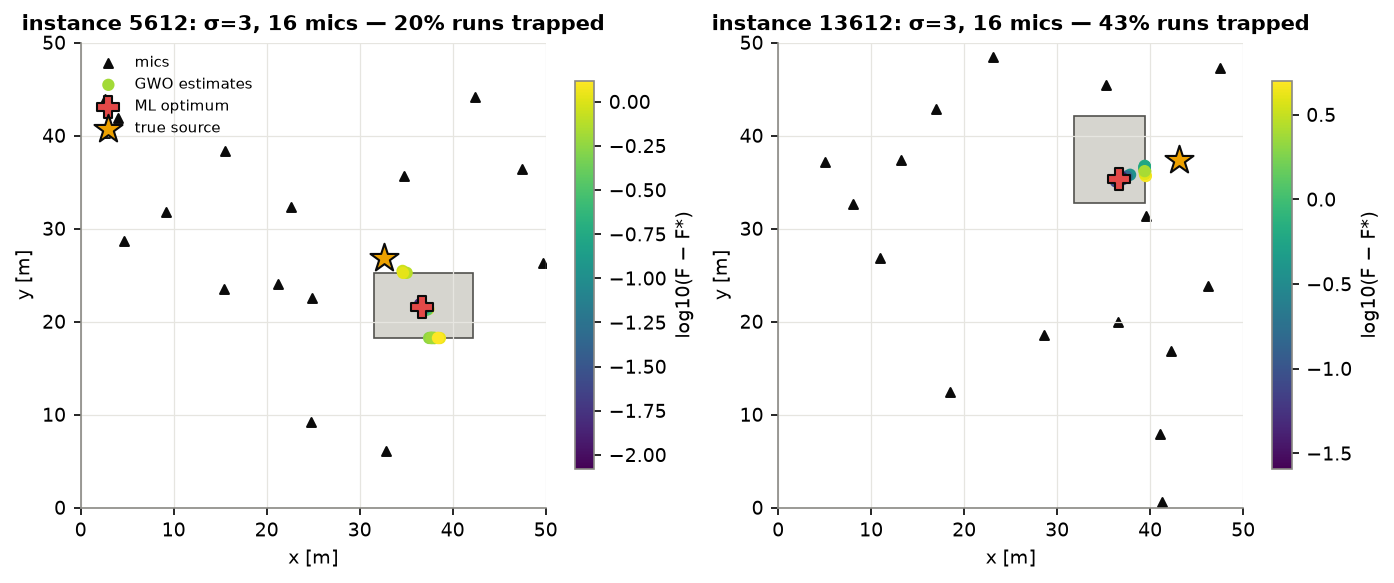

In [28]:
# 8. Fig 15
# ---- Fig 15: failure-mode case study (instance seeds with a poor success rate) -------------
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, sd in zip(axs, (SEED + 1000 * 1, SEED + 1000 * 9)):
    inst_f = generate_instance(sd)
    prob = Problem(inst_f, 3.0, True)
    xm, Fm = reference_optimum(prob, n_starts=100)
    runs = run_many(prob, "gwo")
    X = np.array([r["x"] for r in runs])
    Fv = np.array([r["F"] for r in runs])
    draw_rect(ax, inst_f["box_lo"], inst_f["box_hi"])
    ax.scatter(*prob.mics[:, :2].T, marker="^", c=C_INK, s=18, label="mics")
    sc = ax.scatter(X[:, 0], X[:, 1], c=np.log10(Fv - Fm + 1e-3), cmap="viridis", s=24,
                    zorder=3, label="GWO estimates")
    ax.scatter(*xm[:2], marker="P", s=110, c="#e34948", edgecolor=C_INK, zorder=4,
               label="ML optimum")
    ax.scatter(*inst_f["s_true"][:2], marker="*", s=200, c="#eda100", edgecolor=C_INK, zorder=5,
               label="true source")
    ax.set(xlim=(0, 50), ylim=(0, 50), aspect="equal", xlabel="x [m]", ylabel="y [m]",
           title=f"instance {sd}: σ=3, 16 mics — {np.mean(Fv > Fm + 0.9):.0%} runs trapped")
    fig.colorbar(sc, ax=ax, shrink=0.8, label="log10(F − F*)")
    print(f"instance {sd}: true {inst_f['x_true'].round(2)}  ML {xm.round(2)} F*={Fm:.2f}; "
          f"GWO F range [{Fv.min():.2f}, {Fv.max():.2f}]")
axs[0].legend(fontsize=7, loc="upper left")
savefig(fig, "fig15_failure_cases.png")

**Fig. 15 — failure modes on other instances (σ = 3, 16 mics).**
*Instance 5612 — obstacle-boundary solution:* the ML optimum lies on the **roof** of the obstacle
(z = 4.49 m ≈ box top 4.5 m), 7 m from the true source. The noise makes a source "inside/on" the
obstacle fit best; the penalty keeps solutions out of the box, so the pack splits between two
faces of the box (y ≈ 25 and y ≈ 18) and 20 % of runs get trapped on the wrong face.
*Instance 13612 — S–α–distance ambiguity:* x_ML is 6.6 m from the truth with α̂ = 0.32 vs 0.11 dB/m
and Ŝ = 92.3 vs 89.6 dB: a closer source with stronger attenuation explains the data as well as
the true one. 43 % of runs stop short of x_ML in the flat valley between the two.

  saved figures/fig13_ablation_instances.png


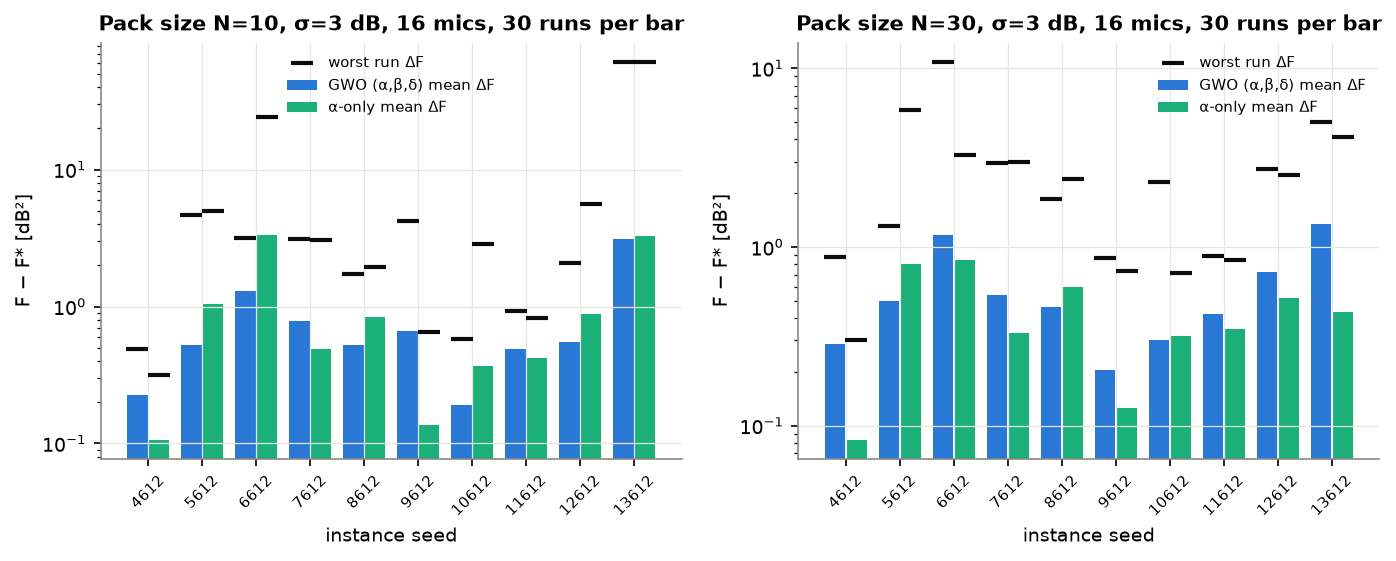

In [29]:
# 8. Fig 13
# ---- Fig 13: cross-instance ablation (three leaders vs α-only) ---------------------------
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, N in zip(axs, (10, 30)):
    a = xabl[(xabl.N == N) & (xabl.guidance == "three")].set_index("instance_seed")
    b = xabl[(xabl.N == N) & (xabl.guidance == "alpha")].set_index("instance_seed")
    pos = np.arange(len(a))
    ax.bar(pos - 0.2, a["dF_mean"], 0.38, color=C_GWO, label="GWO (α,β,δ) mean ΔF")
    ax.bar(pos + 0.2, b["dF_mean"], 0.38, color=C_ALPHA, label="α-only mean ΔF")
    ax.scatter(pos - 0.2, a["dF_max"], marker="_", s=120, c=C_INK, zorder=3)
    ax.scatter(pos + 0.2, b["dF_max"], marker="_", s=120, c=C_INK, zorder=3,
               label="worst run ΔF")
    ax.set_xticks(pos, [str(i) for i in a.index], rotation=45, fontsize=7)
    ax.set(yscale="log", xlabel="instance seed", ylabel="F − F* [dB²]",
           title=f"Pack size N={N}, σ=3 dB, 16 mics, 30 runs per bar")
    ax.legend(fontsize=7)
savefig(fig, "fig13_ablation_instances.png")

**Fig. 13 — ablation across instances** (bars = mean F − F*, dashes = worst run). With N = 10 the
three-leader pack wins on 6/10 instances and prevents the catastrophic worst case of instance
6612; with N = 30 α-only is better on 7/10. Three leaders = robustness insurance for small packs.

In [30]:
# 8b. Failure-mode evidence: premature consensus / too-fast decay
def failure_summary():
    rows = []
    for key in ("stress", "extreme"):
        prob = SCEN[key]
        for lab, runs in (("linear (default)", STRESS[key]["gwo"]),
                          ("exponential (fast decay)",
                           sens_runs_stress[("a(t) schedule", "exponential")]
                           if key == "stress" else run_many(prob, "gwo", schedule="exponential")),
                          ("α-only", ABL[key]["alpha"])):
            X = np.array([r["x"] for r in runs])
            d_ml = np.linalg.norm(X[:, :3] - REF[key]["x"][:3], axis=1)
            Fv = np.array([r["F"] for r in runs])
            coll = leader_stats(runs, REF[key]["x"])["consensus_iter"]
            rows.append(dict(scenario=prob.name, variant=lab,
                             trapped_rate=np.mean(Fv > REF[key]["F"] * 1.02 + 1e-3),
                             wrong_basin_rate=np.mean(d_ml > 3.0),
                             median_consensus_iter=np.nanmedian(coll),
                             worst_F=Fv.max(), F_star=REF[key]["F"]))
    return pd.DataFrame(rows)


fail_tab = failure_summary()
fail_tab.to_csv(os.path.join(RES, "failure_modes.csv"), index=False)
print(fail_tab)

                scenario                   variant  trapped_rate  wrong_basin_rate  median_consensus_iter  worst_F   F_star
0  σ=3, 16 mics (STRESS)          linear (default)        0.5667            0.0667                  298.0  11.0515  10.1697
1  σ=3, 16 mics (STRESS)  exponential (fast decay)        0.7667            0.1333                  279.0  10.8893  10.1697
2  σ=3, 16 mics (STRESS)                    α-only        0.1000            0.0000                  299.0  10.4701  10.1697
3           σ=5, 16 mics          linear (default)        0.1667            0.0667                  298.0  29.7730  29.0009
4           σ=5, 16 mics  exponential (fast decay)        0.3000            0.1000                  279.0  29.8799  29.0009
5           σ=5, 16 mics                    α-only        0.0333            0.0000                  299.0  29.5822  29.0009


### Interpretation — failure modes (trapped = final F > 1.02 F*)
* **Stagnation when a(t) decays too fast:** with the exponential schedule 77 % of stress runs end
  trapped (vs 57 % linear) and 13 % end > 3 m from x_ML (vs 7 %); at σ = 5: 30 % vs 17 %. The
  exploration phase (a > 1) lasts ≈ 40 iterations, the leaders settle on the first reasonable
  valley point and the remaining 250 iterations only polish it.
* **Premature consensus is not the issue with linear a(t):** the leaders agree (< 5 cm) only at
  iteration ≈ 298, i.e. when a → 0. "Trapped" runs of linear GWO are stuck *in the right basin*
  but short of the bottom of the flat valley — a precision, not an exploration, failure.
* **Obstacle-boundary and S–α–distance failures** are instance properties (Fig. 15): they come
  from the data, so a better optimiser converges more reliably *to the wrong-but-optimal* answer.

In [31]:
# 8c. Save machine-readable summary
# Machine-readable summary used by the report
summary = dict(
    instance=dict(box_lo=INST["box_lo"].tolist(), box_hi=INST["box_hi"].tolist(),
                  s_true=INST["s_true"].tolist(), S_true=INST["S_true"], a_true=INST["a_true"],
                  removed=INST["removed"].tolist(), mics=INST["mics"].round(3).tolist(),
                  dist_source_box=float(dist_to_box(INST["s_true"], INST["box_lo"],
                                                    INST["box_hi"])[0])),
    reference={k: dict(x=v["x"].tolist(), F=float(v["F"])) for k, v in REF.items()},
    crb={k: dict(pos_rmse=crb(p)["pos_rmse"], sd=crb(p)["sd"].tolist(),
                 corr_S_a=crb(p)["corr"][3, 4], corr_z_S=crb(p)["corr"][2, 3],
                 cond=crb(p)["cond"]) for k, p in SCEN.items()},
    wilcoxon_main={k: dict(v) for k, v in tests.items()},
    wilcoxon_stress=stress_tests, ablation_p=abl_p,
    ablation_instances=xabl_p.to_dict(orient="index"),
)
with open(os.path.join(RES, "summary.json"), "w") as fh:
    json.dump(summary, fh, indent=2, default=float)
print(f"Done. Total time {time.time() - T0:.1f} s")

Done. Total time 400.4 s
